# Dashboard checks in a browser

**Data source:** the dashboard pages in `../dashboard/` (`index.html`, `detail.html`, `accessibility.html`), built from `build_dashboard.ipynb`.
**Date:** 2026-11-05, updated 2026-11-09 for the refined dashboard
**Authors:** Group 3, Presentation and Visualization (Infovis2627)
**Description:** Opens both screens straight from the folder (a `file://` address, with no server and no internet, exactly as the professor will) in a headless Chromium browser, in the light theme and in the night mode, and checks what they show at first load: no errors, no file requested from the internet, every chart drawn as SVG, the KPIs filled in, the page structure, and that each screen fits a 16:9 window without scrolling (the students' decision when the dashboard was refined). It then uses every interaction of Part 5 as a user would and reads the result back from the page (task 6.5), uses both screens with the keyboard only (task 6.6), checks the text alternatives, data tables, contrast in both themes, 200 % zoom, tablet widths and HTML (task 6.7), and reviews every item of the WCAG checklist.

---

## Contents

1. [Data loading](#1.-Data-loading)
2. [Initial exploration](#2.-Initial-exploration)
3. [Cleaning and preparation](#3.-Cleaning-and-preparation)
4. [Analysis: first load, interactions and keyboard](#4.-Analysis:-checks-at-first-load)
5. [Accessible visualisation: screenshots](#5.-Accessible-visualisation:-screenshots)
6. [Export](#6.-Export)
7. [Conclusions](#Conclusions)

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import sys
from importlib.metadata import version
from pathlib import Path

import pandas as pd

# Playwright drives a real browser. If it is missing: pip install playwright, then: playwright install chromium
from playwright.async_api import async_playwright

DASHBOARD_DIR = Path('../dashboard').resolve()
OUTPUT_DIR = Path('browser_checks_output')
OUTPUT_DIR.mkdir(exist_ok=True)
for old_file in OUTPUT_DIR.glob('*'):          # results of an earlier run (some file names changed with the refined dashboard)
    old_file.unlink()
SCREEN_SIZE = {'width': 1536, 'height': 864}   # a common 16:9 laptop screen, full screen (Part 4 layout)

print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| playwright', version('playwright'))

Python 3.13.18 | pandas 3.0.5 | playwright 1.63.0


## 1. Data loading

The "data" of this notebook are the pages. Each one is opened with a `file://` address.

In [2]:
# ── The pages and the charts each one draws at first load ────────────────────
# The map (C5) shares a box with C4 and is drawn when the Chart / Map switch shows it (I8)
PAGES = {'index.html': ['c1', 'c2', 'c3'], 'detail.html': ['c4', 'c9', 'c7', 'c8']}
CARD_TITLES = ['c1', 'c2', 'c3', 'c4', 'c9']        # charts whose card heading is the chart's own title
page_files = pd.DataFrame([(name, (DASHBOARD_DIR / name).exists(), (DASHBOARD_DIR / name).as_uri())
                           for name in list(PAGES) + ['accessibility.html']], columns=['page', 'exists', 'address'])
page_files

,page,exists,address
0,index.html,True,file:///home/claude/cn/Delivery%201/Delivery%2...
1,detail.html,True,file:///home/claude/cn/Delivery%201/Delivery%2...
2,accessibility.html,True,file:///home/claude/cn/Delivery%201/Delivery%2...


## 2. Initial exploration

The files the pages load, with their size: the data, the chart specs, the theme script and the local copies of the libraries.

In [3]:
# ── Files of the dashboard folder ─────────────────────────────────────────────
pd.DataFrame([(str(path.relative_to(DASHBOARD_DIR)), round(path.stat().st_size / 1024, 1))
              for path in sorted(DASHBOARD_DIR.rglob('*')) if path.is_file()], columns=['file', 'KB'])

,file,KB
0,accessibility.html,10.2
1,dashboard.css,16.8
2,dashboard.js,65.7
3,data.js,773.2
4,detail.html,13.1
5,index.html,8.8
6,lib/.gitkeep,0.0
7,lib/LICENSE-vega-embed.txt,1.5
8,lib/LICENSE-vega-lite.txt,1.5
9,lib/LICENSE-vega.txt,1.5


## 3. Cleaning and preparation

Not applicable.

## 4. Analysis: checks at first load

### 4.1 First load in both themes, and the 16:9 screen

In [4]:
# ── Open each page in each theme and collect what it shows ───────────────────
# Top-level await works in Jupyter; the async API is used because the notebook already runs an event loop.
# The theme follows the computer's setting until Natalia chooses one (theme.js), so the dark run asks for a dark system.

async def check_page(browser, page_name, charts, scheme):
    context = await browser.new_context(viewport=SCREEN_SIZE, device_scale_factor=1, color_scheme=scheme)
    page = await context.new_page()
    problems, requests = [], []
    page.on('console', lambda message: problems.append(f'{message.type}: {message.text}')
            if message.type in ('error', 'warning') else None)
    page.on('pageerror', lambda error: problems.append(f'page error: {error}'))
    page.on('request', lambda request: requests.append(request.url))
    await page.goto((DASHBOARD_DIR / page_name).as_uri())
    await page.wait_for_selector('body[data-dashboard-ready="true"]', timeout=20000)
    found = await page.evaluate("""([charts, cardTitles]) => ({
        lang: document.documentElement.lang,
        theme: document.documentElement.getAttribute('data-theme'),
        page_background: getComputedStyle(document.body).backgroundColor,
        skip_links: [...document.querySelectorAll('.skip-link')].map(a => a.textContent),
        headings: [...document.querySelectorAll('h1, h2, h3, h4')].map(h => h.tagName + ' ' + h.textContent.trim()),
        kpis: [...document.querySelectorAll('.kpi')].map(k => [k.querySelector('dt').textContent,
               k.querySelector('.kpi-value').textContent, k.querySelector('.kpi-context').textContent]),
        showing: document.getElementById('active-filters-text').textContent,
        page_height: document.documentElement.scrollHeight, window_height: innerHeight,
        page_width: document.documentElement.scrollWidth, window_width: innerWidth,
        charts: charts.map(c => {
            const svg = document.querySelector('#' + c + ' svg.marks');
            const title = document.getElementById(c + '-title');
            return {chart: c, svg: !!svg, canvas: !!document.querySelector('#' + c + ' canvas'),
                    marks_with_label: svg ? svg.querySelectorAll('.role-mark [aria-label]').length : 0,
                    heading_as_spec: !cardTitles.includes(c) || title.textContent === DASHBOARD_SPECS[c].title.text,
                    caption_as_spec: document.getElementById(c + '-short').textContent === DASHBOARD_SPECS[c].description};
        })
    })""", [charts, CARD_TITLES])
    await page.screenshot(path=OUTPUT_DIR / f"{page_name.replace('.html', '')}_{scheme}_1536x864.png")
    await context.close()
    found.update(page=page_name, scheme=scheme, problems=problems,
                 internet_requests=[url for url in requests if not url.startswith('file://')],
                 files_loaded=[url.rsplit('/', 1)[-1] for url in requests])
    return found


async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    first_load = [await check_page(browser, name, charts, scheme)
                  for scheme in ['light', 'dark'] for name, charts in PAGES.items()]
    await browser.close()
print('Pages checked:', [(result['page'], result['scheme']) for result in first_load])

Pages checked: [('index.html', 'light'), ('detail.html', 'light'), ('index.html', 'dark'), ('detail.html', 'dark')]


In [5]:
# ── Summary of the checks at first load ──────────────────────────────────────
summary = pd.DataFrame([{
    'page': r['page'], 'system theme': r['scheme'], 'page theme': r['theme'] or 'light',
    'lang="en"': r['lang'] == 'en',
    'errors or warnings': len(r['problems']),
    'files from the internet': len(r['internet_requests']),
    'charts drawn as SVG': sum(c['svg'] and not c['canvas'] for c in r['charts']),
    'charts expected': len(r['charts']),
    'KPIs filled in': sum(value not in ('', '–') for _, value, _ in r['kpis']),
    'skip links': len(r['skip_links']),
    'titles and captions = chart specs': all(c['heading_as_spec'] and c['caption_as_spec'] for c in r['charts']),
    'fits 1536 x 864 without scrolling': r['page_height'] <= r['window_height'] and r['page_width'] <= r['window_width'],
} for r in first_load])
print('Everything as expected:', bool((summary['errors or warnings'] == 0).all() and (summary['files from the internet'] == 0).all()
                                      and (summary['charts drawn as SVG'] == summary['charts expected']).all()
                                      and (summary['KPIs filled in'] == 4).all() and summary['titles and captions = chart specs'].all()
                                      and summary['fits 1536 x 864 without scrolling'].all()
                                      and (summary['page theme'] == summary['system theme']).all()))
summary

Everything as expected: True


,page,system theme,page theme,"lang=""en""",errors or warnings,files from the internet,charts drawn as SVG,charts expected,KPIs filled in,skip links,titles and captions = chart specs,fits 1536 x 864 without scrolling
0,index.html,light,light,True,0,0,3,3,4,2,True,True
1,detail.html,light,light,True,0,0,4,4,4,2,True,True
2,index.html,dark,dark,True,0,0,3,3,4,2,True,True
3,detail.html,dark,dark,True,0,0,4,4,4,2,True,True


In [6]:
# ── What each page shows: KPIs, charts and heading structure (light theme) ───
for r in first_load[:2]:
    print(f"\n{r['page']} | Showing: {r['showing']} | files loaded: {', '.join(r['files_loaded'][1:])}")
    for label, value, context in r['kpis']:
        print(f'  KPI  {label}: {value} ({context})')
    for c in r['charts']:
        print(f"  {c['chart']}: SVG {c['svg']}, marks with an aria-label: {c['marks_with_label']}")
    print('  Headings:', ' / '.join(r['headings']))


index.html | Showing: Both hotels · All years (July 2015 to August 2017) | files loaded: dashboard.css, theme.js, data.js, specs.js, vega-6.2.0.min.js, vega-lite-6.4.1.min.js, vega-embed-7.1.0.min.js, dashboard.js
  KPI  Stays: 75,007 (not cancelled, of 119,201 bookings)
  KPI  Guests: 145,980 (people in those stays)
  KPI  Bookings cancelled: 37.1 % (duplicates included)
  KPI  Median price per night: €94.5 (euros assumed)
  c1: SVG True, marks with an aria-label: 52
  c2: SVG True, marks with an aria-label: 52
  c3: SVG True, marks with an aria-label: 52
  Headings: H1 Hotel guests in Lisbon and the Algarve / H2 Key figures for the selected filters / H2 Charts / H3 In which months do the city and the resort receive most guests? / H3 In which months are most bookings cancelled? / H3 How does the price per night change through the year? / H2 Filters / H3 Selected month / H2 Notes about the data

detail.html | Showing: Both hotels · All years (July 2015 to August 2017) | files loaded: 

In [7]:
# ── Does each screen fit common 16:9 (and other) windows without scrolling? ───
WINDOWS = [(1920, 1080), (1600, 900), (1536, 864), (1366, 768), (1280, 720), (1280, 800)]
fit_rows = []
async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    for width, height in WINDOWS:
        for name in PAGES:
            context = await browser.new_context(viewport={'width': width, 'height': height})
            page = await context.new_page()
            await page.goto((DASHBOARD_DIR / name).as_uri())
            await page.wait_for_selector('body[data-dashboard-ready="true"]')
            size = await page.evaluate('() => [document.documentElement.scrollWidth, document.documentElement.scrollHeight]')
            fit_rows.append({'window': f'{width} x {height}', 'ratio': f'{width / height:.2f}', 'page': name,
                             'scrolls down (px)': max(0, size[1] - height), 'scrolls sideways (px)': max(0, size[0] - width)})
            await context.close()
    await browser.close()
fit_checks = pd.DataFrame(fit_rows)
fit_checks.pivot(index='window', columns='page', values='scrolls down (px)').loc[[f'{w} x {h}' for w, h in WINDOWS]]

page,detail.html,index.html
window,,
1920 x 1080,0,0
1600 x 900,0,0
1536 x 864,0,0
1366 x 768,72,72
1280 x 720,120,120
1280 x 800,40,40


**Finding:** both pages open from the folder with no server and no internet (every file comes from `file://`), with no error or warning in the console, in the light theme and in the night mode (chosen automatically when the computer asks for a dark theme). Every chart is drawn as SVG, the four KPIs are filled in, the pages have `lang="en"`, two skip links and a card heading equal to each chart's title. Both screens fit 16:9 windows of 1536 × 864 px and larger without any scrolling. Smaller windows scroll down a little (the table above): the page keeps a minimum height so that the charts never get too small to read.

### 4.2 Interactions (task 6.5)

Each interaction of Part 5 is done in the browser as a user would (clicking, choosing, pointing), and the result is read back from the page: the KPIs, the marks of the charts, the live regions that a screen reader announces, and the link to the other screen. The expected numbers come from the aggregated tables of `build_dashboard.ipynb` (`data/processed/`).

In [8]:
# ── Expected values, from the tables of task 6.1 ─────────────────────────────
filter_kpis = pd.read_csv('../../data/processed/dashboard_filter_kpis.csv', keep_default_na=False)
country_medians = pd.read_csv('../../data/processed/dashboard_country_medians.csv', keep_default_na=False)
country_hotel_table = pd.read_csv('../../data/processed/dashboard_country_hotel.csv', keep_default_na=False)
country_season_table = pd.read_csv('../../data/processed/dashboard_country_season.csv', keep_default_na=False)
country_map_table = pd.read_csv('../../data/processed/dashboard_country_map.csv', keep_default_na=False)
month_hotel_table = pd.read_csv('../../data/processed/dashboard_month_hotel.csv', keep_default_na=False)
for table in [country_medians, country_hotel_table, country_season_table]:
    table['in_top'] = table['in_top'].astype(str) == 'True'      # read as text or as booleans, depending on pandas

def expected_kpi(hotel, year, column):
    row = filter_kpis[(filter_kpis['hotel_filter'] == hotel) & (filter_kpis['year_filter'] == str(year))].iloc[0]
    return row[column]

def medians_row(hotel, year, country):
    return country_medians[(country_medians['hotel_filter'] == hotel) & (country_medians['year_filter'] == str(year))
                           & (country_medians['country_group'] == country)].iloc[0]

def guests_order(hotel, year):
    """Top 10 countries by guests for the filters, then Other: the order of C4, C7 and C8."""
    rows = country_medians[(country_medians['hotel_filter'] == hotel) & (country_medians['year_filter'] == str(year))
                           & country_medians['in_top'] & (country_medians['country_group'] != 'Other')]
    return rows.sort_values('guests', ascending=False)['country_group'].tolist() + ['Other']

LIST_COUNTRIES = sorted(country_medians.loc[~country_medians['in_top'], 'country_group'].unique())
print('Stays, City Hotel, 2016:', f"{expected_kpi('City Hotel', 2016, 'stays'):,}",
      '| country order (both hotels, all years):', guests_order('Both', 'All'),
      f'| countries in the list outside the top 10: {len(LIST_COUNTRIES)}')

Stays, City Hotel, 2016: 22,662 | country order (both hotels, all years): ['Portugal', 'United Kingdom', 'France', 'Spain', 'Germany', 'Ireland', 'Italy', 'Belgium', 'Netherlands', 'United States', 'Other'] | countries in the list outside the top 10: 53


In [9]:
# ── Helpers that read the page ───────────────────────────────────────────────
READ_PAGE = """() => {
    const text = id => document.getElementById(id) ? document.getElementById(id).textContent.replace(/\\s+/g, ' ').trim() : null;
    const marks = c => document.querySelectorAll('#' + c + ' .role-mark [aria-label]');
    const axis = c => [...document.querySelectorAll('#' + c + ' .role-axis-label text')].map(t => t.textContent).filter(t => isNaN(t.replace(/,/g, '')));
    return {
        showing: text('active-filters-text'), announcer: text('announcer'),
        kpis: Object.fromEntries([...document.querySelectorAll('.kpi')].map(k => [k.querySelector('dt').textContent, k.querySelector('.kpi-value').textContent])),
        link: document.getElementById('link-other-screen').getAttribute('href'),
        month: text('month-details'), country: text('country-details'),
        selected: document.getElementById('country-select') ? document.getElementById('country-select').getAttribute('data-value') : null,
        no_bubble_marks: [...document.querySelectorAll('#country-listbox [data-no-bubble="true"]')].map(o => o.getAttribute('data-value')),
        points: Object.fromEntries(['c1', 'c2', 'c3', 'c4', 'c9', 'c7', 'c8', 'c5'].filter(c => document.querySelector('#' + c + ' svg')).map(c => [c, marks(c).length])),
        visible_rules: Object.fromEntries(['c1', 'c3'].filter(c => document.getElementById(c)).map(
            c => [c, [...document.querySelectorAll('#' + c + ' .mark-rule.role-mark line')].filter(l => l.getAttribute('opacity') !== '0').length])),
        heatmap_outlines: document.querySelectorAll('#c2 .mark-rect.layer_1_marks path').length,
        selected_marks: {
            c4: document.querySelectorAll('#c4 .mark-symbol path[stroke="#1A1A1A"], #c4 .mark-symbol path[stroke="#F2F2F2"]').length,
            c7: document.querySelectorAll('#c7 path[data-selected="true"]').length,
            c8: document.querySelectorAll('#c8 path[data-selected="true"]').length,
            c9: document.querySelectorAll('#c9 .mark-symbol path[fill="#009E73"]').length,
            c5: document.querySelectorAll('#c5 path[stroke="#009E73"]').length},
        c4_order: axis('c4'), c7_order: axis('c7'),
        bubbles: [...marks('c9')].map(m => m.getAttribute('aria-label').split(',')[0]),
        previous_disabled: document.getElementById('previous-country') ? document.getElementById('previous-country').disabled : null,
        next_disabled: document.getElementById('next-country') ? document.getElementById('next-country').disabled : null,
        no_country_disabled: document.getElementById('no-country') ? document.getElementById('no-country').disabled : null,
        tooltip: document.getElementById('vg-tooltip-element') ? document.getElementById('vg-tooltip-element').textContent : '',
        tooltip_visible: !!document.querySelector('#vg-tooltip-element.visible'),
        frame: document.getElementById('frame-month') ? Number(document.getElementById('frame-month').value) : null,
        frame_name: text('frame-month-name'), play: text('play'),
        focus: document.activeElement.id,
        panel_scrolls: document.getElementById('filters').scrollHeight > document.getElementById('filters').clientHeight + 1,
    };
}"""

def count(value):
    return f'{value:,}'

HOTEL_LABELS_TEXT = {'Both': 'Both hotels', 'City Hotel': 'City Hotel (Lisbon)', 'Resort Hotel': 'Resort Hotel (Algarve)'}

async def open_page(browser, address, scheme='light'):
    context = await browser.new_context(viewport=SCREEN_SIZE, color_scheme=scheme)
    page = await context.new_page()
    problems = []
    page.on('console', lambda message: problems.append(message.text) if message.type in ('error', 'warning') else None)
    page.on('pageerror', lambda error: problems.append(str(error)))
    await page.goto(address)
    await page.wait_for_selector('body[data-dashboard-ready="true"]', timeout=20000)
    return context, page, problems

async def settle(page, wait=500):
    await page.wait_for_timeout(wait)          # let Vega redraw and the announcer update

async def mark_centre(page, chart, label_start):
    box = await page.locator(f'#{chart} .role-mark [aria-label^="{label_start}"]').first.bounding_box()
    return box['x'] + box['width'] / 2, box['y'] + box['height'] / 2

async def choose_country(page, name):
    """Open the custom country list with a click and click the country (as a mouse user would)."""
    await page.click('#country-select')
    await page.click(f'#country-listbox [role="option"][data-value="{name}"]')

def expected_no_bubble(hotel, year):
    """Countries of the list that C9 does not draw for the filters: fewer than 20 stays in at least one month (Other has no point)."""
    rows = country_season_table[(country_season_table['hotel_filter'] == hotel) & (country_season_table['year_filter'] == str(year))]
    every_month = set(rows.loc[rows['all_months'].astype(str) == 'True', 'country_group'])
    return sorted(set(country_medians['country_group']) - every_month - {'Other'})

async def click_mark(page, chart, label_start):
    x, y = await mark_centre(page, chart, label_start)
    await page.mouse.click(x, y)
    await settle(page, 900)

checks = []
def check(interaction, what, passed, seen):
    checks.append({'interaction': interaction, 'check': what, 'passes': bool(passed), 'seen in the page': str(seen)[:160]})

print('Helpers ready')

Helpers ready


In [10]:
# ── Main screen: I1, I2, I3, I5, I6, I4, I11 table view, I12 night mode, notes ─
async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    context, page, problems = await open_page(browser, (DASHBOARD_DIR / 'index.html').as_uri())

    await page.check('#hotel-city'); await settle(page)
    seen = await page.evaluate(READ_PAGE)
    check('I1 Hotel filter', 'KPI stays = City Hotel, all years', seen['kpis']['Stays'] == count(expected_kpi('City Hotel', 'All', 'stays')), seen['kpis']['Stays'])
    check('I1 Hotel filter', 'C1-C3 draw only the 26 City Hotel months (points and heatmap cells)', seen['points'] == {'c1': 26, 'c2': 26, 'c3': 26}, seen['points'])
    check('I1 Hotel filter', '"Showing" (a live region) says City Hotel', seen['showing'].startswith('City Hotel'), seen['showing'])

    await page.select_option('#year', '2016'); await settle(page)
    seen = await page.evaluate(READ_PAGE)
    check('I2 Year filter', 'KPI guests = City Hotel, 2016', seen['kpis']['Guests'] == count(expected_kpi('City Hotel', 2016, 'guests')), seen['kpis']['Guests'])
    check('I2 Year filter', 'C1-C3 draw the 12 months of 2016', seen['points'] == {'c1': 12, 'c2': 12, 'c3': 12}, seen['points'])
    check('I2 Year filter', '"Showing" says 2016', seen['showing'] == 'City Hotel (Lisbon) · 2016', seen['showing'])
    check('I3 Filters kept between screens', 'the link to the detail screen carries the filters', seen['link'] == 'detail.html?hotel=City+Hotel&year=2016', seen['link'])

    x, y = await mark_centre(page, 'c1', 'City Hotel, August 2016')
    await page.mouse.move(x, y); await settle(page)
    seen = await page.evaluate(READ_PAGE)
    august = month_hotel_table[(month_hotel_table['arrival_month'] == '2016-08-01') & (month_hotel_table['hotel'] == 'City Hotel')].iloc[0]
    check('I5 Linked month', 'pointing at August 2016 in C1 writes its exact values in the box (a live region)',
          seen['month'].startswith('August 2016') and f"City Hotel: {count(august['guests'])} guests, {august['cancel_rate']:.1f} % cancelled" in seen['month']
          and f"€{august['median_price']:.1f}" in seen['month'], seen['month'])
    check('I5 Linked month', 'a rule marks August 2016 in C1 and C3, and an outline its cell in the C2 heatmap',
          seen['visible_rules'] == {'c1': 1, 'c3': 1} and seen['heatmap_outlines'] == 1, (seen['visible_rules'], seen['heatmap_outlines']))
    check('I6 Tooltips', 'the tooltip shows the month, the hotel and the guests with separators',
          seen['tooltip_visible'] and 'August 2016' in seen['tooltip'] and 'City Hotel' in seen['tooltip']
          and count(august['guests']) in seen['tooltip'] and 'undefined' not in seen['tooltip'], seen['tooltip'])
    await page.screenshot(path=OUTPUT_DIR / 'index_month_linked_1536x864.png')
    await page.mouse.move(5, 5); await settle(page)
    seen = await page.evaluate(READ_PAGE)
    check('I5 Linked month', 'the month stays linked when the pointer leaves', seen['visible_rules'] == {'c1': 1, 'c3': 1} and seen['month'].startswith('August 2016'), seen['visible_rules'])
    x, y = await mark_centre(page, 'c2', 'City Hotel, March 2016')
    await page.mouse.move(x, y); await settle(page)
    seen = await page.evaluate(READ_PAGE)
    check('I5 Linked month', 'pointing at the March 2016 cell of the heatmap links March 2016 in the three charts',
          seen['month'].startswith('March 2016') and seen['visible_rules'] == {'c1': 1, 'c3': 1} and seen['heatmap_outlines'] == 1
          and 'cancelled' in seen['tooltip'], seen['month'][:40])

    await page.click('#reset-filters'); await settle(page)
    seen = await page.evaluate(READ_PAGE)
    check('I4 Reset filters', 'KPIs back to both hotels, all years', seen['kpis']['Stays'] == count(expected_kpi('Both', 'All', 'stays')), seen['kpis']['Stays'])
    check('I4 Reset filters', 'controls back to Both and All', await page.is_checked('#hotel-both') and await page.input_value('#year') == 'All', 'radio and select')
    check('I4 Reset filters', 'the reset is announced', seen['announcer'].startswith('Filters reset'), seen['announcer'])
    check('I4 Reset filters', 'C1-C3 draw all 52 points and cells again', seen['points'] == {'c1': 52, 'c2': 52, 'c3': 52}, seen['points'])

    # I11 Table view
    await page.click('.table-toggle[data-charts="c1"]'); await settle(page)
    table_state = await page.evaluate("""() => ({pressed: document.querySelector('.table-toggle[data-charts="c1"]').getAttribute('aria-pressed'),
        chart_hidden: document.getElementById('c1').hidden, rows: document.querySelectorAll('#c1-table tbody tr').length,
        caption: (document.querySelector('#c1-table caption') || {}).textContent || ''})""")
    check('I11 Table view', 'the Table button swaps C1 for its table (26 months) and says so with aria-pressed',
          table_state['pressed'] == 'true' and table_state['chart_hidden'] and table_state['rows'] == 26 and 'Both hotels' in table_state['caption'], table_state)
    await page.click('.table-toggle[data-charts="c1"]'); await settle(page)
    back = await page.evaluate("() => [document.getElementById('c1').hidden, document.querySelectorAll('#c1 .role-mark [aria-label]').length]")
    check('I11 Table view', 'pressed again, the chart comes back, drawn', back == [False, 52], back)

    # I12 Night mode, remembered for the next visit
    await page.click('#theme-toggle'); await settle(page, 1200)
    night = await page.evaluate("""() => ({theme: document.documentElement.getAttribute('data-theme'),
        pressed: document.getElementById('theme-toggle').getAttribute('aria-pressed'), announcer: document.getElementById('announcer').textContent,
        background: getComputedStyle(document.body).backgroundColor,
        city_line: !!document.querySelector('#c1 path[stroke="#56B4E9"]'), light_city_line: !!document.querySelector('#c1 path[stroke="#0072B2"]')})""")
    check('I12 Night mode', 'the button turns the page and the charts dark (City line sky blue) and is announced',
          night['theme'] == 'dark' and night['pressed'] == 'true' and night['background'] == 'rgb(18, 18, 18)' and night['city_line']
          and not night['light_city_line'] and night['announcer'] == 'Night mode on.', night)
    await page.screenshot(path=OUTPUT_DIR / 'index_night_mode_1536x864.png')
    await page.reload(); await page.wait_for_selector('body[data-dashboard-ready="true"]')
    check('I12 Night mode', 'the choice is remembered when the page is opened again',
          await page.evaluate("document.documentElement.getAttribute('data-theme')") == 'dark', 'after reload')
    await page.click('#theme-toggle'); await settle(page, 1000)
    check('I12 Night mode', 'pressed again, back to the light theme',
          await page.evaluate("document.documentElement.getAttribute('data-theme')") in (None, 'light'), 'light')

    # Notes about the data (a dialog)
    await page.click('#open-notes'); await settle(page, 300)
    opened = await page.evaluate("() => [document.getElementById('notes-dialog').open, !!document.activeElement.closest('dialog')]")
    await page.keyboard.press('Escape'); await settle(page, 300)
    closed = await page.evaluate("() => [document.getElementById('notes-dialog').open, document.activeElement.id]")
    check('Notes about the data', 'the button opens the notes with the focus inside; Escape closes them and the focus goes back',
          opened == [True, True] and closed == [False, 'open-notes'], (opened, closed))
    main_problems = list(problems)
    await context.close()

    # I3: open the detail screen as the link does, with the filters in the address
    context, page, problems = await open_page(browser, (DASHBOARD_DIR / 'detail.html').as_uri() + '?hotel=City+Hotel&year=2016')
    seen = await page.evaluate(READ_PAGE)
    check('I3 Filters kept between screens', 'the detail screen opens with City Hotel and 2016 chosen',
          await page.is_checked('#hotel-city') and await page.input_value('#year') == '2016', seen['showing'])
    check('I3 Filters kept between screens', 'its KPI "countries of origin" is the City Hotel 2016 value',
          seen['kpis']['Countries of origin'] == count(expected_kpi('City Hotel', 2016, 'countries_of_origin')), seen['kpis']['Countries of origin'])
    check('I3 Filters kept between screens', 'C4 has one dot per country (11)', seen['points']['c4'] == 11, seen['points'])
    main_problems += list(problems)
    await context.close()
    await browser.close()
print(f'Main screen and link: {len(checks)} checks, all pass: {all(c["passes"] for c in checks)} | console problems: {main_problems}')

Main screen and link: 25 checks, all pass: True | console problems: []


In [11]:
# ── Detail screen: I7 select a country (click, list, Previous / Next, No country), I9, I8, I10, I11, I1 ─
async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    context, page, problems = await open_page(browser, (DASHBOARD_DIR / 'detail.html').as_uri())
    order = guests_order('Both', 'All')

    seen = await page.evaluate(READ_PAGE)
    check('I7 Select a country', 'no country selected at first: KPIs for all guests, 10 bubbles, nothing highlighted, "No country" disabled',
          seen['selected'] == '' and 'Guests (all countries)' in seen['kpis'] and len(seen['bubbles']) == 10
          and sum(seen['selected_marks'].values()) == 0 and seen['no_country_disabled'], seen['country'][:60])

    await click_mark(page, 'c4', 'France, City Hotel')
    seen = await page.evaluate(READ_PAGE)
    france = medians_row('Both', 'All', 'France')
    check('I7 Select a country', 'a click on a France dot writes France and its guests in the box (a live region)',
          seen['country'].startswith('France') and count(france['guests']) in seen['country'] and seen['announcer'] == 'Selected country: France.', seen['country'][:60])
    check('I7 Select a country', 'France is highlighted in the four charts: 2 outlined dots, a striped box in C7 and C8, a green bubble',
          seen['selected_marks'] == {'c4': 2, 'c7': 1, 'c8': 1, 'c9': 1, 'c5': 0}, seen['selected_marks'])
    check('I7 Select a country', 'the KPIs follow the selection', seen['kpis'].get('Guests from France') == count(france['guests']), seen['kpis'])
    await page.screenshot(path=OUTPUT_DIR / 'detail_country_selected_1536x864.png')

    await click_mark(page, 'c4', 'France, Resort Hotel')
    seen = await page.evaluate(READ_PAGE)
    check('I7 Select a country', 'a second click on France clears the selection', seen['selected'] == '' and seen['announcer'] == 'No country selected.'
          and sum(seen['selected_marks'].values()) == 0, seen['announcer'])
    await click_mark(page, 'c9', 'Germany, January')
    seen = await page.evaluate(READ_PAGE)
    check('I7 Select a country', 'a click on a bubble selects its country (Germany)', seen['selected'] == 'Germany', seen['selected'])
    await click_mark(page, 'c7', 'Germany:')
    seen = await page.evaluate(READ_PAGE)
    check('I7 Select a country', 'a click on the Germany box clears it again', seen['selected'] == '', seen['selected'])

    check('I7 Select a country', 'the country list marks with a point every country without 20 stays in every month (no bubble), and not Other',
          sorted(seen['no_bubble_marks']) == expected_no_bubble('Both', 'All'), f"{len(seen['no_bubble_marks'])} marked")
    await choose_country(page, 'Brazil'); await settle(page, 1500)
    seen = await page.evaluate(READ_PAGE)
    brazil = medians_row('Both', 'All', 'Brazil')
    check('I7 Select a country', 'Brazil, chosen in the list (outside the top 10), is added at the top of C4 and C7 and as an 11th bubble',
          seen['c4_order'][0] == 'Brazil' and seen['c7_order'][0] == 'Brazil' and len(seen['c4_order']) == 12
          and 'Brazil' in seen['bubbles'] and len(seen['bubbles']) == 11, (seen['c4_order'][:3], len(seen['bubbles'])))
    check('I7 Select a country', 'its values are written in the box and the KPIs', seen['country'].startswith('Brazil') and count(brazil['guests']) in seen['country']
          and seen['kpis'].get('Guests from Brazil') == count(brazil['guests']), seen['country'][:60])
    check('I7 Previous / Next', 'Previous is disabled on the first country', seen['previous_disabled'] and not seen['next_disabled'], seen['previous_disabled'])
    check('Fits the screen', 'with a country selected, the filter panel still fits 1536 x 864 without scrolling', not seen['panel_scrolls'], seen['panel_scrolls'])
    await page.click('#next-country'); await settle(page, 1500)
    seen = await page.evaluate(READ_PAGE)
    check('I7 Previous / Next', f'Next goes to the first country by guests ({order[0]}); Brazil leaves the charts',
          seen['selected'] == order[0] and 'Brazil' not in seen['c4_order'] and len(seen['c4_order']) == 11, seen['c4_order'][:2])
    await page.click('#next-country'); await settle(page)
    seen = await page.evaluate(READ_PAGE)
    check('I7 Previous / Next', f'Next again goes to {order[1]}', seen['selected'] == order[1], seen['selected'])

    await page.check('#sort-alphabetical'); await settle(page, 1200)
    seen = await page.evaluate(READ_PAGE)
    check('I9 Sort toggle', 'C4 and C7 become alphabetical with Other last', seen['c4_order'] == sorted(order[:-1]) + ['Other'] and seen['c7_order'] == seen['c4_order'], seen['c4_order'])
    check('I9 Sort toggle', 'the new order is announced', 'alphabetically' in seen['announcer'], seen['announcer'])
    check('I9 Sort toggle', 'the selected country stays selected', seen['selected'] == order[1] and seen['selected_marks']['c4'] == 2, seen['selected_marks'])
    await page.check('#sort-guests'); await settle(page, 1200)
    seen = await page.evaluate(READ_PAGE)
    check('I9 Sort toggle', 'back to the order by guests', seen['c4_order'] == order, seen['c4_order'])

    await page.click('#no-country'); await settle(page, 1200)
    seen = await page.evaluate(READ_PAGE)
    check('I7 Select a country', '"No country" clears the selection and the focus moves to the list (the button is then disabled)',
          seen['selected'] == '' and seen['no_country_disabled'] and seen['focus'] == 'country-select', seen['focus'])

    # I8 Chart / Map switch
    await page.click('label[for="view-map"]'); await settle(page, 1500)
    view = await page.evaluate("""() => ({c4_hidden: document.getElementById('c4').hidden, map: document.querySelectorAll('#c5 .role-mark [aria-label]').length,
        title: document.getElementById('c4-title').textContent, announcer: document.getElementById('announcer').textContent})""")
    check('I8 Chart / Map switch', 'Map replaces the dumbbell by the map in the same box, with the map\'s title, and is announced',
          view['c4_hidden'] and view['map'] > 100 and view['title'] == 'Where do the guests come from?' and 'Map' in view['announcer'], view)
    await click_mark(page, 'c5', 'Spain:')
    seen = await page.evaluate(READ_PAGE)
    check('I8 Chart / Map switch', 'a click on a country of the map selects it (Spain) and outlines it', seen['selected'] == 'Spain' and seen['selected_marks']['c5'] >= 1, seen['selected_marks'])
    await page.screenshot(path=OUTPUT_DIR / 'detail_map_1536x864.png')
    await page.click('.table-toggle[data-charts="c5"]'); await settle(page)
    rows = await page.evaluate("document.querySelectorAll('#c5-table tbody tr').length")
    await page.click('label[for="view-chart"]'); await settle(page, 1200)
    c4_rows = await page.evaluate("document.querySelectorAll('#c4-table tbody tr').length")
    check('I8 Chart / Map switch', 'with the table view on, the switch shows the table of the map (every country with guests) and of the dumbbell',
          rows == expected_kpi('Both', 'All', 'countries_of_origin') and c4_rows == 11, (rows, c4_rows))
    await page.click('.table-toggle[data-charts="c4"]'); await settle(page, 1200)
    check('I8 Chart / Map switch', 'back to the dumbbell chart, drawn', await page.evaluate("document.querySelectorAll('#c4 .role-mark [aria-label]').length") == 22, 'C4 dots')

    # I10 Play the year
    await page.click('#play'); await settle(page, 3400)
    playing = await page.evaluate(READ_PAGE)
    pressed = await page.get_attribute('#play', 'aria-pressed')
    await page.click('#play'); await settle(page, 300)
    paused = await page.evaluate(READ_PAGE)
    await settle(page, 2000)
    still = await page.evaluate(READ_PAGE)
    check('I10 Play the year', 'Play moves the bubbles one month every 1.5 s, says so, and becomes Pause',
          playing['frame'] >= 3 and pressed == 'true' and 'Pause' in playing['play'] and playing['announcer'].startswith('Animation playing'), (playing['frame'], playing['play']))
    check('I10 Play the year', 'Pause stops it on the month shown', 'Play' in paused['play'] and still['frame'] == paused['frame'], (paused['frame'], still['frame']))
    month_name = still['frame_name']
    check('I10 Play the year', 'the bubbles, the slider and its label show the same month', all(f', {month_name}:' in label for label in
          await page.evaluate("[...document.querySelectorAll('#c9 .role-mark [aria-label]')].map(m => m.getAttribute('aria-label'))")), month_name)
    await page.focus('#frame-month'); await page.keyboard.press('End'); await settle(page, 800)
    december = await page.evaluate(READ_PAGE)
    check('I10 Play the year', 'the slider works with the keyboard (End: December)', december['frame'] == 12 and december['frame_name'] == 'December', december['frame_name'])
    await page.click('#play'); await settle(page, 400)
    restart = await page.evaluate(READ_PAGE)
    await page.click('#play'); await settle(page, 300)
    check('I10 Play the year', 'at the last month, Play starts again from January', restart['frame'] == 1, restart['frame'])

    # I11 on the wide card: both box plots become tables
    await page.click('.table-toggle[data-charts="c7 c8"]'); await settle(page)
    tables = await page.evaluate("() => [document.querySelectorAll('#c7-table tbody tr').length, document.querySelectorAll('#c8-table tbody tr').length, document.getElementById('c7').hidden]")
    check('I11 Table view', 'the Table button of the box plots shows both tables (11 countries each)', tables == [11, 11, True], tables)
    await page.click('.table-toggle[data-charts="c7 c8"]'); await settle(page)

    await page.check('#hotel-resort'); await settle(page, 1200)
    seen = await page.evaluate(READ_PAGE)
    check('I1 Hotel filter', 'on the detail screen: C4 shows one dot per country and the KPIs change',
          seen['points']['c4'] == 11 and seen['kpis']['Countries of origin'] == count(expected_kpi('Resort Hotel', 'All', 'countries_of_origin')),
          seen['kpis']['Countries of origin'])
    await page.select_option('#year', '2015'); await settle(page, 1200)
    slider = await page.evaluate("() => [document.getElementById('frame-month').min, document.getElementById('frame-month').max]")
    seen = await page.evaluate(READ_PAGE)
    check('I7 Select a country', 'the points of the country list follow the filters (Resort Hotel, 2015)',
          sorted(seen['no_bubble_marks']) == expected_no_bubble('Resort Hotel', 2015), f"{len(seen['no_bubble_marks'])} marked")
    check('I2 Year filter', 'with 2015 (July to December only) the month slider of C9 runs from 7 to 12', slider == ['7', '12'], slider)
    detail_problems = list(problems)
    await context.close()
    await browser.close()

interaction_checks = pd.DataFrame(checks)
print(f'{len(interaction_checks)} checks, all pass: {interaction_checks["passes"].all()} | console problems on the detail screen: {detail_problems}')
interaction_checks

57 checks, all pass: True | console problems on the detail screen: []


,interaction,check,passes,seen in the page
0,I1 Hotel filter,"KPI stays = City Hotel, all years",True,"46,082"
1,I1 Hotel filter,C1-C3 draw only the 26 City Hotel months (poin...,True,"{'c1': 26, 'c2': 26, 'c3': 26}"
2,I1 Hotel filter,"""Showing"" (a live region) says City Hotel",True,City Hotel (Lisbon) · All years (July 2015 to ...
3,I2 Year filter,"KPI guests = City Hotel, 2016",True,"44,421"
4,I2 Year filter,C1-C3 draw the 12 months of 2016,True,"{'c1': 12, 'c2': 12, 'c3': 12}"
5,I2 Year filter,"""Showing"" says 2016",True,City Hotel (Lisbon) · 2016
6,I3 Filters kept between screens,the link to the detail screen carries the filters,True,detail.html?hotel=City+Hotel&year=2016
7,I5 Linked month,pointing at August 2016 in C1 writes its exact...,True,"August 2016City Hotel: 4,836 guests, 37.0 % ca..."
8,I5 Linked month,"a rule marks August 2016 in C1 and C3, and an ...",True,"({'c1': 1, 'c3': 1}, 1)"
9,I6 Tooltips,"the tooltip shows the month, the hotel and the...",True,MonthAugust 2016HotelCity HotelGuests who stay...


**Finding (task 6.5):** every planned interaction works in the browser and changes both what Natalia sees and what a screen reader announces. The hotel and year filters change the KPIs, the charts and the "Showing" line, and the link to the other screen carries them; the reset button brings everything back and says so; pointing at a month (in a line chart or in the heatmap) links it in the three charts and writes its exact values; tooltips show the values. On the detail screen no country is selected at first; a click on a dot, bubble, box or country of the map selects it everywhere and a second click clears it; a country from the list is added at the top of the charts; Previous, Next and "No country" work and the focus is never lost. The sort toggle, the Chart / Map switch, Play / Pause and the month slider, the Table buttons and the night mode (remembered for the next visit) also work. The arrow keys on the data marks come in task 6.6.

### 4.3 Keyboard and focus (task 6.6)

The same pages are used with the keyboard only, as the wcag-accessibility skill asks: Tab through every control and chart, the arrow keys inside each chart, `Alt` + up/down arrow between series, Home/End, Enter and Escape. After each key the check reads which element has the focus, what the chart's live region announces, whether the SVG focus overlay draws a ring, and what the visible boxes say.

In [12]:
# ── Helpers for the keyboard checks ───────────────────────────────────────────
READ_FOCUS = """() => {
    const e = document.activeElement;
    const chart = e.closest('.chart-container');
    const style = getComputedStyle(e);
    const box = document.getElementById('keyboard-value');
    return {
        id: e.id, tag: e.tagName.toLowerCase(), label: e.getAttribute('aria-label') || (e.textContent || '').trim().slice(0, 60),
        chart: chart ? chart.id : null,
        announced: chart && chart.querySelector('.chart-announcer') ? chart.querySelector('.chart-announcer').textContent : '',
        ring_shapes: chart && chart.querySelector('.focus-overlay') ? chart.querySelector('.focus-overlay').childElementCount : 0,
        rings_elsewhere: [...document.querySelectorAll('.focus-overlay')].filter(o => !chart || o.parentElement !== chart).reduce((n, o) => n + o.childElementCount, 0),
        outline: style.outlineStyle + ' ' + style.outlineWidth,
        value_box: box && !box.hidden ? box.textContent : '',
        dimmed: chart ? [...chart.querySelectorAll('[tabindex]')].filter(m => m.style.opacity === '0.4').length : 0,
    };
}"""

async def press(page, *keys, wait=400):
    for key in keys:
        await page.keyboard.press(key)
    await page.wait_for_timeout(wait)
    return await page.evaluate(READ_FOCUS)

async def tab_to(page, test, limit=40):
    """Press Tab until the focused element passes a test (as a keyboard user would)."""
    for _ in range(limit):
        focus = await press(page, 'Tab', wait=250)
        if test(focus):
            return focus
    raise AssertionError('not reached with Tab')

def stop_name(focus):
    return focus['chart'] or focus['id'] or focus['tag']

print('Keyboard helpers ready')

Keyboard helpers ready


In [13]:
# ── Main screen with the keyboard only ───────────────────────────────────────
async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    context, page, problems = await open_page(browser, (DASHBOARD_DIR / 'index.html').as_uri())

    # Tab order and visible focus on every stop of one full round
    stops = [await press(page, 'Tab', wait=250) for _ in range(16)]
    tab_order = [stop_name(f) for f in stops]
    check('Keyboard: Tab', 'Tab order: skip links, screen links, help, night mode, then each chart after its Table button, hotel, year, reset, notes',
          tab_order == ['a', 'a', 'a', 'link-other-screen', 'a', 'theme-toggle', 'button', 'c1', 'button', 'c2', 'button', 'c3',
                        'hotel-both', 'year', 'reset-filters', 'open-notes'], tab_order)
    html_stops = [f for f in stops if not f['chart']]
    check('Keyboard: visible focus', 'every control shows a 3 px solid focus outline (blue, white on the dark header band)',
          all(f['outline'] == 'solid 3px' for f in html_stops), sorted({f['outline'] for f in html_stops}))
    check('Keyboard: visible focus', 'every chart stop shows an SVG focus ring (2 shapes), never more than one ring on the page',
          all(f['ring_shapes'] == 2 and f['rings_elsewhere'] == 0 for f in stops if f['chart']), [f['ring_shapes'] for f in stops if f['chart']])
    check('Keyboard: skip link', 'the first Tab stop is the skip link to the charts', stops[0]['label'] == 'Skip to the charts', stops[0]['label'])

    # Inside C1: arrows, Alt + arrows, Home / End, Enter / Escape
    await page.focus('#c1 [tabindex="0"]')
    focus = await press(page, 'ArrowRight', 'ArrowRight', 'ArrowRight')
    check('Keyboard: chart', 'three right arrows reach October 2015 of the City Hotel', focus['label'].startswith('City Hotel, October 2015'), focus['label'])
    check('Keyboard: announcement', 'the live region says series, position and value',
          focus['announced'].startswith('Hotel: City Hotel. Month 4 of 26: City Hotel, October 2015'), focus['announced'][:80])
    check('Keyboard: active series', 'the other hotel is dimmed (26 points at opacity 0.4)', focus['dimmed'] == 26, focus['dimmed'])
    seen = await page.evaluate(READ_PAGE)
    check('Keyboard: I5 linked month', 'the focused month is linked in C1-C3 and written in the box',
          seen['visible_rules'] == {'c1': 1, 'c3': 1} and seen['heatmap_outlines'] == 2 and seen['month'].startswith('October 2015'), seen['month'][:60])
    check('Keyboard: value visible', 'the value box shows the focused value', focus['value_box'].startswith('City Hotel, October 2015'), focus['value_box'])
    await page.screenshot(path=OUTPUT_DIR / 'index_keyboard_focus_1536x864.png')
    focus = await press(page, 'Alt+ArrowDown')
    check('Keyboard: series', 'Alt + down arrow goes to the Resort Hotel, same month',
          focus['label'].startswith('Resort Hotel, October 2015') and focus['announced'].startswith('Hotel: Resort Hotel. Month 4 of 26'), focus['announced'][:70])
    focus = await press(page, 'Alt+ArrowUp')
    check('Keyboard: series', 'Alt + up arrow comes back to the City Hotel', focus['label'].startswith('City Hotel, October 2015'), focus['label'])
    focus = await press(page, 'End')
    check('Keyboard: chart', 'End goes to the last month (August 2017)', focus['label'].startswith('City Hotel, August 2017'), focus['label'])
    focus = await press(page, 'ArrowRight')
    check('Keyboard: chart', 'right arrow on the last point stays there', focus['label'].startswith('City Hotel, August 2017'), focus['label'])
    focus = await press(page, 'Home')
    check('Keyboard: chart', 'Home goes to the first month (July 2015)', focus['label'].startswith('City Hotel, July 2015'), focus['label'])
    focus = await press(page, 'Escape')
    check('Keyboard: value visible', 'Escape hides the value box (WCAG 1.4.13)', focus['value_box'] == '', focus['value_box'])
    focus = await press(page, 'Enter')
    check('Keyboard: value visible', 'Enter shows it again', focus['value_box'].startswith('City Hotel, July 2015'), focus['value_box'])
    focus = await press(page, 'Tab')
    left = await page.evaluate("() => [document.querySelector('#c1 .focus-overlay').childElementCount, [...document.querySelectorAll('#c1 [tabindex]')].filter(m => m.style.opacity === '0.4').length]")
    check('Keyboard: chart', 'Tab leaves C1 for the Table button of C2; the ring and the dimming of C1 are removed',
          focus['tag'] == 'button' and left == [0, 0], f"{focus['tag']}, C1 ring and dimmed: {left}")

    # Inside the heatmap: reading order, Alt + arrows between the hotels
    focus = await press(page, 'Tab')
    check('Keyboard: chart', 'the heatmap C2 starts at its first cell, City Hotel July 2015', focus['chart'] == 'c2' and focus['label'].startswith('City Hotel, July 2015'), focus['label'])
    focus = await press(page, 'ArrowRight')
    check('Keyboard: chart', 'right arrow in the heatmap goes to the next month (August 2015)', focus['label'].startswith('City Hotel, August 2015'), focus['label'])
    focus = await press(page, 'Alt+ArrowDown')
    check('Keyboard: series', 'Alt + down arrow in the heatmap goes to the Resort Hotel, same month', focus['label'].startswith('Resort Hotel, August 2015'), focus['label'])

    # Filters and the night mode with the keyboard
    focus = await tab_to(page, lambda f: f['id'] == 'hotel-both')
    focus = await press(page, 'ArrowDown')
    seen = await page.evaluate(READ_PAGE)
    check('Keyboard: I1 filter', 'down arrow in the hotel group chooses the City Hotel and updates the KPIs',
          focus['id'] == 'hotel-city' and seen['kpis']['Stays'] == count(expected_kpi('City Hotel', 'All', 'stays')), seen['kpis']['Stays'])
    await press(page, 'Tab')
    await page.keyboard.press('ArrowDown'); await page.wait_for_timeout(400)
    seen = await page.evaluate(READ_PAGE)
    check('Keyboard: I2 filter', 'down arrow on the year list chooses 2015', await page.input_value('#year') == '2015' and seen['showing'].endswith('2015 (July to December only)'), seen['showing'])
    focus = await press(page, 'Tab', 'Enter')
    seen = await page.evaluate(READ_PAGE)
    check('Keyboard: I4 reset', 'Enter on Reset brings back both hotels and all years', seen['kpis']['Stays'] == count(expected_kpi('Both', 'All', 'stays')), seen['announcer'])
    await page.focus('#theme-toggle'); await press(page, 'Enter', wait=1200)
    check('Keyboard: I12 night mode', 'Enter on "Night mode" turns the page dark', await page.evaluate("document.documentElement.getAttribute('data-theme')") == 'dark', 'dark')
    await page.focus('#c1 [tabindex="0"]')
    focus = await press(page, 'ArrowRight')
    ring = await page.evaluate("() => [...document.querySelectorAll('#c1 .focus-overlay circle')].map(c => c.getAttribute('stroke'))")
    check('Keyboard: visible focus', 'in the night mode the chart focus ring is still white and blue (3:1 on both backgrounds)', ring == ['#FFFFFF', '#0066CC'], ring)
    await press(page, 'Shift+Tab', 'Shift+Tab')
    main_keyboard_problems = list(problems)
    await context.close()

    # Reduced motion: the page honours the user's setting
    context = await browser.new_context(viewport=SCREEN_SIZE, reduced_motion='reduce')
    page = await context.new_page()
    await page.goto((DASHBOARD_DIR / 'index.html').as_uri())
    duration = await page.evaluate("getComputedStyle(document.querySelector('#reset-filters')).transitionDuration")
    check('Reduced motion', 'with prefers-reduced-motion, transitions last 0.01 ms or less', duration in ('1e-05s', '0s'), duration)
    await context.close()
    await browser.close()
print(f'Checks so far: {len(checks)} | all pass: {all(c["passes"] for c in checks)} | console problems: {main_keyboard_problems}')

Checks so far: 83 | all pass: True | console problems: []


In [14]:
# ── Detail screen with the keyboard only ─────────────────────────────────────
async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    context, page, problems = await open_page(browser, (DASHBOARD_DIR / 'detail.html').as_uri())

    stops = [await press(page, 'Tab', wait=250) for _ in range(23)]
    tab_order = [stop_name(f) for f in stops]
    check('Keyboard: Tab', 'detail screen Tab order: links, night mode, Chart/Map switch, Table, C4, Table, C9, Play, slider, Table, C7, C8, filters, list, Next, sort, notes',
          tab_order == ['a', 'a', 'link-other-screen', 'a', 'a', 'theme-toggle', 'view-chart', 'button', 'c4', 'button', 'c9', 'play',
                        'frame-month', 'button', 'c7', 'c8', 'hotel-both', 'year', 'reset-filters', 'country-select', 'next-country',
                        'sort-guests', 'open-notes'], tab_order)
    check('Keyboard: visible focus', 'every control of the detail screen shows a 3 px solid focus outline',
          all(f['outline'] == 'solid 3px' for f in stops if not f['chart']), sorted({f['outline'] for f in stops if not f['chart']}))

    focus = await tab_to(page, lambda f: f['chart'] == 'c4')
    check('Keyboard: chart', 'Tab enters C4 on its first dot (Portugal, City Hotel)', focus['label'].startswith('Portugal, City Hotel') and focus['ring_shapes'] == 2, focus['label'])
    check('Keyboard: announcement', 'on entering C4 the live region also says how to move and that Enter selects or clears',
          'Alt plus up or down arrow' in focus['announced'] and 'Enter: select or clear this country' in focus['announced'], focus['announced'][-90:])
    focus = await press(page, 'ArrowDown')
    seen = await page.evaluate(READ_PAGE)
    check('Keyboard: focus and selection', 'down arrow moves to United Kingdom and only shows its value: nothing is selected yet',
          focus['label'].startswith('United Kingdom, City Hotel') and seen['selected'] == '', focus['label'][:40])
    check('Keyboard: announcement', 'the live region says hotel, position and value',
          focus['announced'].startswith('Hotel: City Hotel. Country 2 of 11: United Kingdom, City Hotel'), focus['announced'][:90])
    focus = await press(page, 'Enter', wait=1200)
    seen = await page.evaluate(READ_PAGE)
    check('Keyboard: I7 select a country', 'Enter selects United Kingdom everywhere and the focus stays on its dot',
          seen['selected'] == 'United Kingdom' and seen['selected_marks']['c4'] == 2 and focus['chart'] == 'c4'
          and focus['label'].startswith('United Kingdom, City Hotel') and focus['ring_shapes'] == 2, (seen['selected'], focus['label'][:30]))
    await page.screenshot(path=OUTPUT_DIR / 'detail_keyboard_focus_1536x864.png')
    focus = await press(page, 'Alt+ArrowDown')
    check('Keyboard: series', 'Alt + down arrow goes to the Resort Hotel dot, same country', focus['label'].startswith('United Kingdom, Resort Hotel'), focus['label'])
    focus = await press(page, 'Enter', wait=1200)
    seen = await page.evaluate(READ_PAGE)
    check('Keyboard: I7 select a country', 'Enter again on the selected country clears it', seen['selected'] == '', seen['announcer'])

    focus = await tab_to(page, lambda f: f['chart'] == 'c9')
    focus = await press(page, 'ArrowRight')
    check('Keyboard: chart', 'C9: the arrow keys move between the bubbles, announced with their position', focus['chart'] == 'c9' and 'Country 2 of 10' in focus['announced'], focus['announced'][:70])
    focus = await press(page, 'Tab')
    check('Keyboard: I10 play', 'after C9 comes the Play button', focus['id'] == 'play', focus['id'])
    focus = await tab_to(page, lambda f: f['chart'] == 'c7')
    focus = await press(page, 'ArrowDown')
    check('Keyboard: chart', 'C7: down arrow goes to the second box (United Kingdom)', focus['label'].startswith('United Kingdom:'), focus['label'])
    focus = await press(page, 'Tab')
    check('Keyboard: chart', 'Tab goes from C7 to C8, on its first box', focus['chart'] == 'c8' and focus['label'].startswith('Portugal:'), focus['label'])

    # The map with the keyboard
    await page.focus('#view-chart'); await press(page, 'ArrowRight', wait=1500)
    focus = await press(page, 'Tab', 'Tab', wait=500)
    check('Keyboard: I8 switch', 'right arrow on the switch shows the map; Tab reaches it after its Table button, on the country with most guests',
          focus['chart'] == 'c5' and focus['label'].startswith('Portugal:') and focus['ring_shapes'] == 2, focus['label'])
    focus = await press(page, 'ArrowRight')
    check('Keyboard: chart', 'right arrow on the map goes to the second country by guests (United Kingdom)', focus['label'].startswith('United Kingdom:'), focus['label'])

    # The custom country list with the keyboard (WAI-ARIA select-only combobox)
    await page.focus('#country-select'); await press(page, 'Enter', wait=300)
    opened = await page.evaluate("() => [document.getElementById('country-select').getAttribute('aria-expanded'), !!document.getElementById('country-select').getAttribute('aria-activedescendant')]")
    await page.keyboard.type('br'); await page.wait_for_timeout(200)
    active = await page.evaluate("() => (document.querySelector('#country-listbox [role=\"option\"].active') || {}).getAttribute ? document.querySelector('#country-listbox [role=\"option\"].active').getAttribute('data-value') : ''")
    focus = await press(page, 'Enter', wait=1200)
    seen = await page.evaluate(READ_PAGE)
    check('Keyboard: country list', 'Enter opens the list, typing "br" goes to Brazil, Enter chooses it and the focus stays on the list',
          opened == ['true', True] and active == 'Brazil' and seen['selected'] == 'Brazil' and focus['id'] == 'country-select', (opened, active, seen['selected']))
    await press(page, 'ArrowDown', 'ArrowDown', 'Escape', wait=400)
    seen = await page.evaluate(READ_PAGE)
    check('Keyboard: country list', 'Escape closes the list without changing the country', seen['selected'] == 'Brazil'
          and await page.get_attribute('#country-select', 'aria-expanded') == 'false', seen['selected'])
    await page.focus('#no-country'); await press(page, 'Enter', wait=1200)

    # Previous / Next and No country with the keyboard
    await page.focus('#next-country'); await press(page, 'Enter', wait=1200)
    seen = await page.evaluate(READ_PAGE)
    check('Keyboard: I7 Previous / Next', 'Enter on Next with no country selected selects the first country (Portugal)', seen['selected'] == 'Portugal', seen['selected'])
    check('Keyboard: I7 Previous / Next', 'Previous is disabled on the first country, Next is not', seen['previous_disabled'] and not seen['next_disabled'], (seen['previous_disabled'], seen['next_disabled']))
    await page.focus('#no-country'); focus = await press(page, 'Enter', wait=1200)
    check('Keyboard: I7 Previous / Next', 'Enter on "No country" clears it and the focus moves to the list, not lost', focus['id'] == 'country-select', focus['id'])
    detail_keyboard_problems = list(problems)
    await context.close()
    await browser.close()

keyboard_checks = pd.DataFrame([c for c in checks if c['interaction'].startswith(('Keyboard', 'Reduced'))])
print(f'Keyboard checks: {len(keyboard_checks)} | all pass: {keyboard_checks["passes"].all()} | console problems: {detail_keyboard_problems}')
keyboard_checks

Keyboard checks: 46 | all pass: True | console problems: []


,interaction,check,passes,seen in the page
0,Keyboard: Tab,"Tab order: skip links, screen links, help, nig...",True,"['a', 'a', 'a', 'link-other-screen', 'a', 'the..."
1,Keyboard: visible focus,every control shows a 3 px solid focus outline...,True,['solid 3px']
2,Keyboard: visible focus,every chart stop shows an SVG focus ring (2 sh...,True,"[2, 2, 2]"
3,Keyboard: skip link,the first Tab stop is the skip link to the charts,True,Skip to the charts
4,Keyboard: chart,three right arrows reach October 2015 of the C...,True,"City Hotel, October 2015: 3,624 guests"
5,Keyboard: announcement,"the live region says series, position and value",True,"Hotel: City Hotel. Month 4 of 26: City Hotel, ..."
6,Keyboard: active series,the other hotel is dimmed (26 points at opacit...,True,26
7,Keyboard: I5 linked month,the focused month is linked in C1-C3 and writt...,True,"October 2015City Hotel: 3,624 guests, 39.1 % c..."
8,Keyboard: value visible,the value box shows the focused value,True,"City Hotel, October 2015: 3,624 guests"
9,Keyboard: series,"Alt + down arrow goes to the Resort Hotel, sam...",True,Hotel: Resort Hotel. Month 4 of 26: Resort Hot...


### 4.4 Review of the Operability items of the WCAG checklist

Each item of the "Operabilidad" list of the wcag-accessibility skill, with the result and its evidence (the checks above, by name). Items that are not met, or met in a different way, say so.

In [15]:
# ── Operability items of the skill's checklist ───────────────────────────────
def passed(prefix):
    rows = [c for c in checks if c['interaction'].startswith(prefix)]
    return bool(rows) and all(c['passes'] for c in rows)

operability = pd.DataFrame([
    ('Every data point can be reached with the arrow keys', 'met' if passed('Keyboard: chart') else 'NOT MET',
     'All 8 charts: points of C1 and C3, cells of C2, dots of C4, bubbles of C9, boxes of C7 and C8, countries of the map C5 (checks "Keyboard: chart")'),
    ('Every control can be reached with Tab in a logical order', 'met' if passed('Keyboard: Tab') else 'NOT MET',
     'Skip links, screen links, help, night mode, charts in reading order (each after its own buttons), then the filter panel'),
    ('Focus always visible (focus-visible, never outline: none without replacement)', 'met' if passed('Keyboard: visible focus') else 'NOT MET',
     '3 px outline on every control (white on the dark header band); white and blue SVG ring on every chart stop, in both themes'),
    ('In multi-series charts Alt + up/down changes series keeping the index', 'met' if passed('Keyboard: series') else 'NOT MET',
     'C1-C3 (hotel), C4 (hotel dot of the same country)'),
    ('Changing series announces "series, point N of M: value" (aria-live)', 'met' if passed('Keyboard: announcement') else 'NOT MET',
     'Each chart has its own polite live region'),
    ('The active series is highlighted (opacity) against the others', 'met' if passed('Keyboard: active series') else 'NOT MET',
     'Other series at opacity 0.4 while the focus is in the chart, restored when it leaves'),
    ('The selected category and its exact value are always visible next to the chart', 'met' if passed('Keyboard: value visible') and passed('Keyboard: I5') else 'NOT MET',
     '"Selected month" and "Selected country" boxes; value box next to the focused mark'),
    ('Previous / Next buttons disabled at the ends', 'met' if passed('Keyboard: I7 Previous') and passed('I7 Previous') else 'NOT MET', 'Previous disabled on the first country, Next on the last'),
    ('Focus and selection are distinguished without colour alone', 'met' if passed('Keyboard: focus and selection') else 'NOT MET',
     'Focus: white and blue ring and value box, nothing selected; selection (Enter or click): band, bold label, outline, stripes, green, and the box text'),
    ('Navigation controls fit on a phone', 'not applicable', 'The dashboard is for a computer or a tablet (architecture.md): designed for a 16:9 screen and checked down to a 768 px wide tablet'),
    ('The SVG focus indicator is drawn in its own group above the marks (correct z-order)', 'met (adapted)',
     'Drawn in an SVG overlay outside Vega\'s SVG, the "correct solution" of the same skill section; never covered by titles or legends'),
    ('Never CSS outline on SVG elements; stroke / circle / rhombus by mark type', 'met (adapted)',
     'Boxes, cells and countries: double rectangle; points and bubbles: double circle; no line mark takes the focus (the points of each line do), so no rhombus is needed'),
    ('The focus group is cleared on blur', 'met' if passed('Keyboard: chart') else 'NOT MET', 'Check "Tab leaves C1": ring and dimming removed'),
    ('The focus announces its position and scrolls the element into view', 'met' if passed('Keyboard: announcement') else 'NOT MET', 'scrollIntoView on every focus'),
    ('Focus on a dark background uses a double ring (3:1, WCAG 2.4.11)', 'met' if passed('Keyboard: visible focus') else 'NOT MET', 'White and blue double ring on the marks, checked in the night mode too'),
    ('The focused element is not hidden by fixed elements (WCAG 2.4.11)', 'met', 'The pages have no fixed header or footer'),
    ('Touch targets at least 24 x 24 px (44 recommended)', 'partly met',
     'Every control is at least 24 px (WCAG 2.5.8): links, buttons and selects 40 px high, radio rows, the switch, Table and Play 32 px, the month slider 24 px, '
     'smaller than the 44 px of the first build so that each screen fits a 16:9 window; the data points (about 8 px) are smaller, but every one is also reachable by keyboard, the list of countries and Previous / Next (section 4.6)'),
    ('Skip link at the start of the page', 'met' if passed('Keyboard: skip link') else 'NOT MET', 'Two skip links: to the charts and to the filters'),
    ('No change of context on focus (WCAG 3.2.1)', 'met',
     'Focusing a month links it in the charts of the same page; on the detail screen focus only shows the value and Enter selects, so nothing changes by focus alone'),
    ('Moving content can be paused, stopped or hidden (WCAG 2.2.2)', 'met' if passed('I10') else 'NOT MET', 'The animation of C9 starts only with Play, can be paused, stops at December and has a slider'),
    ('Reduced motion respected', 'met' if passed('Reduced motion') else 'NOT MET', 'CSS prefers-reduced-motion; the only animation (C9) changes the month in steps and only after Play'),
], columns=['Operability item (wcag-accessibility skill)', 'result', 'evidence'])
print(operability['result'].value_counts().to_dict())
operability

{'met': 17, 'met (adapted)': 2, 'not applicable': 1, 'partly met': 1}


,Operability item (wcag-accessibility skill),result,evidence
0,Every data point can be reached with the arrow...,met,"All 8 charts: points of C1 and C3, cells of C2..."
1,Every control can be reached with Tab in a log...,met,"Skip links, screen links, help, night mode, ch..."
2,"Focus always visible (focus-visible, never out...",met,3 px outline on every control (white on the da...
3,In multi-series charts Alt + up/down changes s...,met,"C1-C3 (hotel), C4 (hotel dot of the same country)"
4,"Changing series announces ""series, point N of ...",met,Each chart has its own polite live region
5,The active series is highlighted (opacity) aga...,met,Other series at opacity 0.4 while the focus is...
6,The selected category and its exact value are ...,met,"""Selected month"" and ""Selected country"" boxes;..."
7,Previous / Next buttons disabled at the ends,met,"Previous disabled on the first country, Next o..."
8,Focus and selection are distinguished without ...,met,"Focus: white and blue ring and value box, noth..."
9,Navigation controls fit on a phone,not applicable,The dashboard is for a computer or a tablet (a...


**Finding (task 6.6):** with the keyboard only, every control and every data mark of both screens can be reached and used: Tab stops once per chart, the arrow keys move inside it, `Alt` + up/down arrow changes hotel, Home/End jump to the ends, Escape and Enter hide and show the value. Each move is announced with its position and value and a white-and-blue ring drawn above the chart shows the focus, also in the night mode. On the main screen moving through a chart also links the month; on the detail screen it only shows the value, and Enter selects or clears the country, so focus and selection are never confused. One Operability item is only partly met: the data points are smaller than 24 px, which is allowed here because the same action can be done in other ways (keyboard, the list, Previous/Next). The phone item does not apply.

### 4.5 Text alternatives, data tables and fill patterns (task 6.7)

Each chart must have a short and a long text alternative and a data table (shown with its "Table" button), and the heatmap and the selected country must not be shown by colour alone. The long texts and the tables are written by `dashboard.js` for the current filters; here they are read from the page and compared with pandas for two filter states on each screen.

In [16]:
# ── Expected texts and tables, from the tables of task 6.1 (same formats as the page) ─
MONTHS = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']

def in_filters(table, hotel, year):
    keep = pd.Series(True, index=table.index)
    if hotel != 'Both':
        keep &= table['hotel'] == hotel
    if year != 'All':
        keep &= table['year'] == int(year)
    return table[keep]

def for_filters(table, hotel, year):
    return table[(table['hotel_filter'] == hotel) & (table['year_filter'] == str(year))]

def js_percent(value):
    from decimal import Decimal, ROUND_HALF_UP
    return str(Decimal(float(value)).quantize(Decimal('0.1'), rounding=ROUND_HALF_UP)) + ' %'

def trimmed(value):
    """Like the page: rounded to one decimal (half up), without a trailing .0 (2, 2.5, 128.3)."""
    from decimal import Decimal, ROUND_HALF_UP
    return f'{float(Decimal(str(float(value))).quantize(Decimal("0.1"), rounding=ROUND_HALF_UP)):g}'

def month_label(month):
    return MONTHS[int(month[5:7]) - 1] + ' ' + month[:4]

def expected_month_rows(hotel, year, cell):
    rows = in_filters(month_hotel_table, hotel, year)
    hotels = ['City Hotel', 'Resort Hotel'] if hotel == 'Both' else [hotel]
    return [[month_label(month)] + [cell(rows[(rows['arrival_month'] == month) & (rows['hotel'] == h)].iloc[0]) for h in hotels]
            for month in sorted(rows['arrival_month'].unique())]

def expected_c4_rows(hotel, year, order):
    rows = in_filters(country_hotel_table[country_hotel_table['in_top']], hotel, year).groupby(['country_group', 'hotel'])['guests'].sum()
    hotels = ['City Hotel', 'Resort Hotel'] if hotel == 'Both' else [hotel]
    totals = {h: rows.xs(h, level='hotel').sum() for h in hotels}
    return [[c] + [f"{js_percent(100 * rows.get((c, h), 0) / totals[h])} ({count(int(rows.get((c, h), 0)))})" for h in hotels] for c in order]

def expected_c5_rows(hotel, year):
    rows = in_filters(country_map_table, hotel, year).groupby('country_name')['guests'].sum().reset_index()
    rows = rows[rows['guests'] > 0].sort_values(['guests', 'country_name'], ascending=[False, True])
    return [[r.country_name, count(int(r.guests))] for r in rows.itertuples()]

def expected_box_rows(prefix, hotel, year, order):
    rows = for_filters(country_medians, hotel, year).set_index('country_group')
    return [[c, trimmed(rows.loc[c, f'{prefix}_median']), f"{trimmed(rows.loc[c, f'{prefix}_q1'])} to {trimmed(rows.loc[c, f'{prefix}_q3'])}",
             f"{trimmed(rows.loc[c, f'{prefix}_low'])} to {trimmed(rows.loc[c, f'{prefix}_high'])}", count(int(rows.loc[c, 'guests']))] for c in order]

def expected_c9_rows(hotel, year, month):
    rows = for_filters(country_season_table, hotel, year)
    rows = rows[(rows['calendar_month'] == month) & (rows['all_months'].astype(str) == 'True') & rows['in_top'] & (rows['country_group'] != 'Other')]
    rows = rows.sort_values(['share', 'country_group'], ascending=[False, True])
    return [[r.country_group, js_percent(r.share), trimmed(r.median_lead_time), count(int(r.guests))] for r in rows.itertuples()]

READ_ALTERNATIVES = """names => Object.fromEntries(names.map(n => {
    const svg = document.querySelector('#' + n + ' svg.marks');
    return [n, {
        short: document.getElementById(n + '-short').textContent,
        long: document.getElementById(n + '-long').textContent,
        svg_role: svg ? svg.getAttribute('role') : null, svg_label: svg ? svg.getAttribute('aria-label') : null,
        figure_described_by: document.getElementById(n + '-short').closest('figure').getAttribute('aria-describedby'),
        table: [...document.querySelectorAll('#' + n + '-table tbody tr')].map(tr => [...tr.children].map(td => td.textContent)),
        caption: (document.querySelector('#' + n + '-table caption') || {}).textContent || '',
    }];
}))"""

async def open_tables(page, toggles):
    for charts in toggles:
        await page.click(f'.table-toggle[data-charts="{charts}"]')
    await settle(page)

print('Expected-value helpers ready')

Expected-value helpers ready


In [17]:
# ── Check the text alternatives and the tables in two filter states per screen ─
alternative_checks_start = len(checks)
async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    for hotel, year in [('Both', 'All'), ('City Hotel', '2016')]:
        address = (DASHBOARD_DIR / 'index.html').as_uri() + f'?hotel={hotel.replace(" ", "+")}&year={year}'
        context, page, problems = await open_page(browser, address)
        state = f'{hotel}, {year}'
        svg_labels = await page.evaluate(READ_ALTERNATIVES, ['c1', 'c2', 'c3'])
        check('Text alternatives', f'C1-C3 ({state}): short text = chart description, also the SVG aria-label (role img)',
              all(a['short'] == a['svg_label'] and a['svg_role'] == 'img' and a['figure_described_by'].endswith('-description') for a in svg_labels.values()), svg_labels['c1']['short'])
        await open_tables(page, ['c1', 'c2', 'c3'])
        alt = await page.evaluate(READ_ALTERNATIVES, ['c1', 'c2', 'c3'])
        rows = in_filters(month_hotel_table, hotel, year)
        city = rows[rows['hotel'] == 'City Hotel']
        top = city.loc[city['guests'].idxmax()]
        top_text = f"City Hotel: highest in {month_label(top['arrival_month'])} ({count(int(top['guests']))} guests)"
        check('Text alternatives', f'C1 long text ({state}) names the busiest month of the City Hotel with its guests', top_text in alt['c1']['long'], alt['c1']['long'][:120])
        check('Text alternatives', f'C2 long text ({state}) explains the colour classes', 'Colour classes' in alt['c2']['long'], alt['c2']['long'][:100])
        check('Data tables', f'C1 table ({state}) = pandas guests, every month and hotel', alt['c1']['table'] == expected_month_rows(hotel, year, lambda r: count(int(r['guests']))), f"{len(alt['c1']['table'])} rows")
        check('Data tables', f'C2 table ({state}) = pandas % cancelled', alt['c2']['table'] == expected_month_rows(hotel, year, lambda r: js_percent(r['cancel_rate'])), alt['c2']['table'][:1])
        check('Data tables', f'C3 table ({state}) = pandas median price', alt['c3']['table'] == expected_month_rows(hotel, year, lambda r: f"€{r['median_price']:.1f}"), alt['c3']['table'][:1])
        check('Data tables', f'C1-C3 tables ({state}) have a caption with the chart and the filters',
              all(HOTEL_LABELS_TEXT[hotel].split(' (')[0] in a['caption'] and a['caption'].startswith('Data of the chart') for a in alt.values()), alt['c1']['caption'])
        await context.close()

    for hotel, year in [('Both', 'All'), ('Resort Hotel', '2017')]:
        address = (DASHBOARD_DIR / 'detail.html').as_uri() + f'?hotel={hotel.replace(" ", "+")}&year={year}'
        context, page, problems = await open_page(browser, address)
        state = f'{hotel}, {year}'
        order = guests_order(hotel, year)
        svg_labels = await page.evaluate(READ_ALTERNATIVES, ['c4', 'c9', 'c7', 'c8'])
        check('Text alternatives', f'C4, C9, C7, C8 ({state}): short and long texts present, SVG role img and aria-label',
              all(a['short'] == a['svg_label'] and a['svg_role'] == 'img' and len(a['long']) > 40 for a in svg_labels.values()), svg_labels['c9']['long'][:100])
        await open_tables(page, ['c4', 'c9', 'c7 c8'])
        alt = await page.evaluate(READ_ALTERNATIVES, ['c4', 'c9', 'c7', 'c8'])
        frame = await page.evaluate("Number(document.getElementById('frame-month').value)")
        check('Data tables', f'C4 table ({state}) = pandas shares and guests, in the order of the chart', alt['c4']['table'] == expected_c4_rows(hotel, year, order), alt['c4']['table'][:2])
        check('Data tables', f'C7 table ({state}) = pandas quartiles and whiskers of the nights', alt['c7']['table'] == expected_box_rows('nights', hotel, year, order), alt['c7']['table'][:1])
        check('Data tables', f'C8 table ({state}) = pandas quartiles and whiskers of the days booked ahead', alt['c8']['table'] == expected_box_rows('lead', hotel, year, order), alt['c8']['table'][:1])
        check('Data tables', f'C9 table ({state}, month {frame}) = pandas share, days ahead and guests of each bubble', alt['c9']['table'] == expected_c9_rows(hotel, year, frame), alt['c9']['table'][:1])
        await page.click('label[for="view-map"]'); await settle(page, 1500)
        alt_map = await page.evaluate(READ_ALTERNATIVES, ['c5'])
        check('Data tables', f'map table ({state}) = pandas guests of every country with guests', alt_map['c5']['table'] == expected_c5_rows(hotel, year), f"{len(alt_map['c5']['table'])} countries")
        check('Text alternatives', f'map ({state}): long text present', len(alt_map['c5']['long']) > 40, alt_map['c5']['long'][:80])
        await page.click('.table-toggle[data-charts="c5"]'); await settle(page, 1200)
        await page.click('.table-toggle[data-charts="c7 c8"]'); await settle(page, 1200)
        await choose_country(page, order[1]); await settle(page, 1200)
        pattern = await page.evaluate("""() => ({boxes: [...document.querySelectorAll('#c7 path[data-selected="true"], #c8 path[data-selected="true"]')].map(p => p.getAttribute('fill')),
            map_outline: document.querySelectorAll('#c5 path[stroke="#009E73"]').length})""")
        check('Fill pattern', f'the selected country ({state}, {order[1]}) has a green box with white stripes in C7 and C8, and an outline on the map',
              pattern['boxes'] == ['url(#pattern-selected)'] * 2 and pattern['map_outline'] >= 1, pattern)
        await context.close()

    # The heatmap: dots whose density grows with the class (pattern-rules), redrawn in the night mode
    context, page, problems = await open_page(browser, (DASHBOARD_DIR / 'index.html').as_uri())
    dots = await page.evaluate("""() => {
        const cells = [...document.querySelectorAll('#c2 .mark-rect.layer_0_marks path')];
        const overlay = document.querySelector('#c2 .dots-overlay');
        return {cells: cells.length, dots: overlay ? overlay.querySelectorAll('circle, rect').length : 0,
                hidden: overlay ? overlay.getAttribute('aria-hidden') : null, pointer: overlay ? getComputedStyle(overlay).pointerEvents : null,
                subtitle: document.getElementById('c2-subtitle').textContent}; }""")
    check('Fill pattern', 'the heatmap has a dot overlay (hidden from screen readers, not clickable) and its subtitle explains the dots',
          dots['cells'] == 52 and dots['dots'] > 0 and dots['hidden'] == 'true' and dots['pointer'] == 'none' and 'more dots: more cancelled' in dots['subtitle'], dots)
    await page.click('#theme-toggle'); await settle(page, 1500)
    night_dots = await page.evaluate("() => document.querySelectorAll('#c2 .dots-overlay circle, #c2 .dots-overlay rect').length")
    check('Fill pattern', 'the dots are drawn again in the night mode', night_dots == dots['dots'], night_dots)
    await context.close()
    await browser.close()
alternative_checks = pd.DataFrame(checks[alternative_checks_start:])
print(f'{len(alternative_checks)} checks, all pass: {alternative_checks["passes"].all()}')
alternative_checks

32 checks, all pass: True


,interaction,check,passes,seen in the page
0,Text alternatives,"C1-C3 (Both, All): short text = chart descript...",True,Line chart of the number of guests per month i...
1,Text alternatives,"C1 long text (Both, All) names the busiest mon...",True,"Both hotels, All years (July 2015 to August 20..."
2,Text alternatives,"C2 long text (Both, All) explains the colour c...",True,"Both hotels, All years (July 2015 to August 20..."
3,Data tables,"C1 table (Both, All) = pandas guests, every mo...",True,26 rows
4,Data tables,"C2 table (Both, All) = pandas % cancelled",True,"[['July 2015', '67.3 %', '23.2 %']]"
5,Data tables,"C3 table (Both, All) = pandas median price",True,"[['July 2015', '€80.0', '€123.0']]"
6,Data tables,"C1-C3 tables (Both, All) have a caption with t...",True,"Data of the chart ""In which months do the city..."
7,Text alternatives,"C1-C3 (City Hotel, 2016): short text = chart d...",True,Line chart of the number of guests per month i...
8,Text alternatives,"C1 long text (City Hotel, 2016) names the busi...",True,"City Hotel (Lisbon), 2016. City Hotel: highest..."
9,Text alternatives,"C2 long text (City Hotel, 2016) explains the c...",True,"City Hotel (Lisbon), 2016. Colour classes of 1..."


### 4.6 Contrast and text size in both themes, 200 % zoom and tablet widths, page structure and HTML validity

In [18]:
# ── Contrast and size of every visible text, measured in the browser, light and night ─
TEXT_AUDIT = """() => {
    const lum = c => { const v = c.map(x => { x /= 255; return x <= 0.03928 ? x / 12.92 : Math.pow((x + 0.055) / 1.055, 2.4); });
                       return 0.2126 * v[0] + 0.7152 * v[1] + 0.0722 * v[2]; };
    const rgb = s => (s.match(/[\\d.]+/g) || []).map(Number);
    const ratio = (a, b) => { const [l1, l2] = [lum(a), lum(b)].sort((x, y) => y - x); return (l1 + 0.05) / (l2 + 0.05); };
    const background = el => { for (let e = el; e; e = e.parentElement) {
        const c = rgb(getComputedStyle(e).backgroundColor); if (c.length === 3 || (c.length === 4 && c[3] > 0)) return c.slice(0, 3); }
        return [255, 255, 255]; };
    const items = [];
    const visible = el => { const r = el.getBoundingClientRect(); return r.width > 0 && r.height > 0 && !el.closest('.sr-only, [hidden], dialog:not([open])'); };
    document.querySelectorAll('body *:not(svg *)').forEach(el => {
        const own = [...el.childNodes].some(n => n.nodeType === 3 && n.textContent.trim());
        if (!own || !visible(el)) return;
        const s = getComputedStyle(el);
        const size = parseFloat(s.fontSize), bold = parseInt(s.fontWeight) >= 700;
        items.push({kind: 'page text', text: el.textContent.trim().slice(0, 40), size,
                    ratio: ratio(rgb(s.color), background(el)), large: size >= 24 || (bold && size >= 18.66)});
    });
    document.querySelectorAll('svg.marks text').forEach(t => {
        if (!t.textContent.trim() || !visible(t) || t.getAttribute('opacity') === '0' || Number(t.getAttribute('fill-opacity')) === 0) return;
        const s = getComputedStyle(t);
        const size = parseFloat(t.getAttribute('font-size') || s.fontSize);
        items.push({kind: 'chart text', text: t.textContent.trim().slice(0, 40), size,
                    ratio: ratio(rgb(s.fill), background(t.closest('.chart-container'))), large: size >= 24});
    });
    return items;
}"""

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    audits = []
    for scheme in ['light', 'dark']:
        for name in ['index.html', 'detail.html', 'accessibility.html']:
            context = await browser.new_context(viewport=SCREEN_SIZE, color_scheme=scheme)
            page = await context.new_page()
            await page.goto((DASHBOARD_DIR / name).as_uri())
            states = ['as opened']
            if name != 'accessibility.html':
                await page.wait_for_selector('body[data-dashboard-ready="true"]')
            for item in await page.evaluate(TEXT_AUDIT):
                audits.append({'theme': scheme, 'page': name, **item})
            if name == 'detail.html':      # also with a country selected (bold label, selection box) and with the map
                await choose_country(page, 'Brazil'); await page.wait_for_timeout(1200)
                await page.click('label[for="view-map"]'); await page.wait_for_timeout(1500)
                for item in await page.evaluate(TEXT_AUDIT):
                    audits.append({'theme': scheme, 'page': name + ' (Brazil, map)', **item})
            await context.close()
    await browser.close()

text_audit = pd.DataFrame(audits)
text_audit['needed'] = text_audit['large'].map({True: 3.0, False: 4.5})
text_audit['passes'] = text_audit['ratio'] >= text_audit['needed']
contrast_summary = text_audit.groupby(['theme', 'page', 'kind']).agg(texts=('text', 'size'), lowest_contrast=('ratio', 'min'),
                                                                      failing=('passes', lambda s: int((~s).sum())), smallest_px=('size', 'min')).round(2)
print('Texts below the WCAG AA contrast:', int((~text_audit['passes']).sum()))
print('Page texts smaller than 16 px:', sorted(text_audit.query("kind == 'page text' and size < 16")['size'].unique()),
      '| chart texts smaller than 12 px:', int((text_audit.query("kind == 'chart text'")['size'] < 12).sum()))
contrast_summary

Texts below the WCAG AA contrast: 0
Page texts smaller than 16 px: [] | chart texts smaller than 12 px: 0


texts  lowest_contrast  failing  \
theme page                      kind                                         
dark  accessibility.html        page text    124             7.22        0   
      detail.html               page text     58             7.22        0   
      detail.html (Brazil, map) page text     62             7.22        0   
      index.html                page text     44             7.22        0   
light accessibility.html        page text    124             5.57        0   
      detail.html               page text     58             4.58        0   
      detail.html (Brazil, map) page text     62             4.58        0   
      index.html                page text     44             4.58        0   

                                           smallest_px  
theme page                      kind                    
dark  accessibility.html        page text         16.0  
      detail.html               page text         16.0  
      detail.html (Brazil, map) page text         16.0  
      index.html                page text         16.0  
light accessibility.html        page text         16.0  
      detail.html               page text         16.0  
      detail.html (Brazil, map) page text         16.0  
      index.html                page text         16.0

In [19]:
# ── 200 % zoom and tablet widths: nothing lost, no sideways scrolling of the page ─
# 200 % zoom of a 1536 x 864 window is a 768 x 432 CSS-pixel viewport at device scale 2.
LAYOUT_CASES = [('200 % zoom (1536 x 864 at 200 %)', {'width': 768, 'height': 432}, 2),
                ('tablet landscape 1024 x 768', {'width': 1024, 'height': 768}, 1),
                ('tablet portrait 768 x 1024', {'width': 768, 'height': 1024}, 1)]
LAYOUT_READ = """() => ({
    page_scrolls_sideways: document.documentElement.scrollWidth > window.innerWidth + 1,
    charts_scrolling_inside: [...document.querySelectorAll('.chart-container')].filter(c => c.offsetParent && c.scrollWidth > c.clientWidth + 1).map(c => c.id),
    one_column: document.getElementById('filters').getBoundingClientRect().top > document.getElementById('charts').getBoundingClientRect().top,
    charts_drawn: [...document.querySelectorAll('.chart-container')].filter(c => c.offsetParent).every(c => c.querySelector('svg.marks') && c.querySelector('svg.marks').getBoundingClientRect().height > 100),
})"""
layout_rows = []
async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    for case, viewport, scale in LAYOUT_CASES:
        for name in ['index.html', 'detail.html']:
            context = await browser.new_context(viewport=viewport, device_scale_factor=scale)
            page = await context.new_page()
            await page.goto((DASHBOARD_DIR / name).as_uri())
            await page.wait_for_selector('body[data-dashboard-ready="true"]')
            layout = await page.evaluate(LAYOUT_READ)
            # every Tab stop of one round is visible on the screen when focused (nothing hidden or cut)
            hidden_stops, stops = [], 0
            for _ in range(40):
                await page.keyboard.press('Tab')
                info = await page.evaluate("""() => { const e = document.activeElement; const r = e.getBoundingClientRect();
                    return {tag: e.tagName, id: e.id, w: r.width, h: r.height, inside: r.right > 0 && r.bottom > 0 && r.left < innerWidth && r.top < innerHeight}; }""")
                if info['tag'] == 'BODY':
                    break
                stops += 1
                if not (info['w'] > 0 and info['h'] > 0 and info['inside']):
                    hidden_stops.append(info['id'] or info['tag'])
            file_name = f"{name.replace('.html', '')}_{case.split(' ')[0].replace('%', 'pct')}_{viewport['width']}x{viewport['height']}.png"
            await page.screenshot(path=OUTPUT_DIR / file_name, full_page=True)
            layout_rows.append({'case': case, 'page': name, 'page scrolls sideways': layout['page_scrolls_sideways'],
                                'one column (filters under the charts)': layout['one_column'], 'every chart drawn, taller than 100 px': layout['charts_drawn'],
                                'Tab stops': stops, 'Tab stops not visible': len(hidden_stops),
                                'charts that scroll inside their box': ', '.join(layout['charts_scrolling_inside']) or '-'})
            await context.close()
    await browser.close()
layout_checks = pd.DataFrame(layout_rows)
print('No sideways page scrolling, every chart drawn and every Tab stop visible:',
      bool((~layout_checks['page scrolls sideways']).all() and layout_checks['every chart drawn, taller than 100 px'].all()
           and (layout_checks['Tab stops not visible'] == 0).all()))
layout_checks

No sideways page scrolling, every chart drawn and every Tab stop visible: True


,case,page,page scrolls sideways,one column (filters under the charts),"every chart drawn, taller than 100 px",Tab stops,Tab stops not visible,charts that scroll inside their box
0,200 % zoom (1536 x 864 at 200 %),index.html,False,True,True,16,0,-
1,200 % zoom (1536 x 864 at 200 %),detail.html,False,True,True,23,0,-
2,tablet landscape 1024 x 768,index.html,False,True,True,16,0,-
3,tablet landscape 1024 x 768,detail.html,False,True,True,23,0,-
4,tablet portrait 768 x 1024,index.html,False,True,True,16,0,-
5,tablet portrait 768 x 1024,detail.html,False,True,True,23,0,-


In [20]:
# ── Page structure: names of the controls, ARIA references, ids, language; HTML validity ─
STRUCTURE_READ = """() => {
    const name = e => e.getAttribute('aria-label') || (e.id && document.querySelector('label[for="' + e.id + '"]') || {}).textContent
                      || (e.labels && e.labels[0] && e.labels[0].textContent) || e.textContent.trim();
    const controls = [...document.querySelectorAll('a[href], button, input, select, summary')];
    const refs = [...document.querySelectorAll('[aria-labelledby], [aria-describedby], [aria-controls]')].flatMap(e =>
        ['aria-labelledby', 'aria-describedby', 'aria-controls'].flatMap(a => (e.getAttribute(a) || '').split(' ').filter(Boolean)));
    const ids = [...document.querySelectorAll('[id]')].map(e => e.id);
    return {
        lang: document.documentElement.lang,
        controls: controls.length,
        controls_without_name: controls.filter(e => !(name(e) || '').trim()).map(e => e.outerHTML.slice(0, 60)),
        broken_references: refs.filter(r => !document.getElementById(r)),
        duplicate_ids: ids.filter((id, i) => ids.indexOf(id) !== i),
        charts_without_role_img: [...document.querySelectorAll('svg.marks')].filter(s => s.getAttribute('role') !== 'img' || !s.getAttribute('aria-label')).length,
        live_regions: document.querySelectorAll('[aria-live]').length,
        help_link: !!document.querySelector('a[href="accessibility.html"]'),
        headings: [...document.querySelectorAll('h1, h2, h3, h4')].map(h => h.tagName).join(' '),
        // target size of the visible controls (a radio is clicked on its whole row, a switch option on its label)
        smallest_target_px: Math.min(...[...document.querySelectorAll('a[href], button, select, input[type=range], .radio, .segmented label')]
            .filter(e => e.offsetParent && !e.closest('.sr-only')).map(e => { const r = e.getBoundingClientRect(); return Math.round(Math.min(r.width, r.height)); })),
        button_heights_px: [...new Set([...document.querySelectorAll('button, select, .radio, .segmented label, a.skip-link, nav a')]
            .filter(e => e.offsetParent).map(e => Math.round(e.getBoundingClientRect().height)))].sort().join(', '),
    };
}"""
structure_rows = []
async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    for name in ['index.html', 'detail.html', 'accessibility.html']:
        context = await browser.new_context(viewport=SCREEN_SIZE)
        page = await context.new_page()
        await page.goto((DASHBOARD_DIR / name).as_uri())
        if name != 'accessibility.html':
            await page.wait_for_selector('body[data-dashboard-ready="true"]')
        found = await page.evaluate(STRUCTURE_READ)
        structure_rows.append({'page': name, **{k: (len(v) if isinstance(v, list) else v) for k, v in found.items()}})
        if name == 'accessibility.html':
            help_text = await page.inner_text('main')
        await context.close()
    await browser.close()
structure_checks = pd.DataFrame(structure_rows)

# HTML validity with html-validate (needs Node.js and, the first time, internet to download it; skipped otherwise)
import shutil, subprocess
if shutil.which('npx'):
    result = subprocess.run(['npx', '-y', 'html-validate@11.16.3', '--formatter', 'text', 'index.html', 'detail.html', 'accessibility.html'],
                            cwd=DASHBOARD_DIR, capture_output=True, text=True, timeout=300, shell=sys.platform == 'win32')
    html_validation = 'no errors' if result.returncode == 0 else result.stdout.strip()[:500]
else:
    html_validation = 'skipped: Node.js (npx) is not installed on this computer'
print('html-validate 11.16.3 on the three pages:', html_validation)

HELP_SECTIONS = ['Moving around a page', 'Moving inside a chart', 'Filters and other controls', 'Shortcuts of this dashboard', 'Accessibility problems?']
HELP_TOPICS = ['Night mode', 'Play', 'Table', 'No country', 'Map']
print('Help page sections present:', {section: section in help_text for section in HELP_SECTIONS})
print('Help page explains the new controls:', {topic: topic in help_text for topic in HELP_TOPICS})
structure_checks

html-validate 11.16.3 on the three pages: no errors
Help page sections present: {'Moving around a page': True, 'Moving inside a chart': True, 'Filters and other controls': True, 'Shortcuts of this dashboard': True, 'Accessibility problems?': True}
Help page explains the new controls: {'Night mode': True, 'Play': True, 'Table': True, 'No country': True, 'Map': True}


,page,lang,controls,controls_without_name,broken_references,duplicate_ids,charts_without_role_img,live_regions,help_link,headings,smallest_target_px,button_heights_px
0,index.html,en,16,0,0,0,0,6,True,H1 H2 H2 H3 H3 H3 H2 H3 H2,30,"30, 32, 40, 42"
1,detail.html,en,25,0,0,0,0,7,True,H1 H2 H2 H3 H3 H3 H4 H4 H2 H3 H2,24,"30, 32, 40, 42"
2,accessibility.html,en,3,0,0,0,0,0,False,H1 H2 H2 H2 H2 H2 H2,44,44


### 4.7 Review of the Perception, Comprehensibility, Robustness and help-page items of the WCAG checklist

In [21]:
# ── The other items of the skill's checklist, with their result and evidence ──
contrast_failures = int((~text_audit['passes']).sum())
small_page_text = sorted(text_audit.query("kind == 'page text' and size < 16")['size'].round(1).unique())
small_chart_text = int((text_audit.query("kind == 'chart text'")['size'] < 12).sum())
no_side_scroll = bool((~layout_checks['page scrolls sideways']).all() and (layout_checks['Tab stops not visible'] == 0).all()
                      and layout_checks['every chart drawn, taller than 100 px'].all())
structure_ok = bool((structure_checks['controls_without_name'] == 0).all() and (structure_checks['broken_references'] == 0).all()
                    and (structure_checks['duplicate_ids'] == 0).all() and (structure_checks['charts_without_role_img'] == 0).all())
help_ok = all(section in help_text for section in HELP_SECTIONS) and all(topic in help_text for topic in HELP_TOPICS)

def result(ok):
    return 'met' if ok else 'NOT MET'

review = pd.DataFrame([
    ('Perception', 'Text contrast at least 4.5:1 (3:1 large text and UI)', result(contrast_failures == 0),
     f'{len(text_audit)} visible texts measured on the three pages in both themes, lowest ratio {text_audit["ratio"].min():.2f}:1; data colours checked in Part 4 and build_dashboard (all at least 3:1 in both themes)'),
    ('Perception', 'Colour is never the only channel (plus pattern or shape)', result(passed('Fill pattern')),
     'Hotels: colour + line style + point shape + label; heatmap: colour classes + dots; selected country: green + stripes + outline + band + bold label + text; map classes named in the legend, values in the table'),
    ('Perception', 'Each chart has a text alternative (figcaption + .sr-only)', result(passed('Text alternatives')),
     'Short text (SVG aria-label and figcaption) and long text with the main values for the current filters'),
    ('Perception', 'SVG renderer only, never canvas', result(bool((summary['charts drawn as SVG'] == summary['charts expected']).all())), 'Checked at first load in both themes'),
    ('Perception', 'Animations respect prefers-reduced-motion', result(passed('Reduced motion') and passed('I10')),
     'CSS transitions off with the setting; the C9 animation is never automatic, moves in steps and can be paused'),
    ('Comprehensibility', 'Every control has an associated label', result(structure_ok), 'Every link, button, input, select and summary has a name'),
    ('Comprehensibility', 'State changes are announced with aria-live', result(passed('I1') and passed('Keyboard: announcement')),
     'Showing line, Selected month / country boxes, chart live regions, hidden announcer (reset, sort, switch, animation, night mode)'),
    ('Comprehensibility', 'The page language is declared', result(bool((structure_checks['lang'] == 'en').all())), 'lang="en" on the three pages'),
    ('Comprehensibility', 'Data in an external file, not in the HTML', 'met (adapted)', 'data.js loaded with script src instead of data.json, so the pages open by double-click (architecture.md)'),
    ('Comprehensibility', 'Chart titles in plain language (COGA)', 'met', "Titles are Natalia's questions, for example 'In which months are most bookings cancelled?'"),
    ('Comprehensibility', 'Numbers with thousands separators and explicit units', result(passed('Data tables')), 'Tooltips, boxes, KPIs and tables: 145,980 guests, 37.1 %, €94.5'),
    ('Comprehensibility', 'Active filters always visible', 'met', '"Showing" line under the filters'),
    ('Comprehensibility', 'Reset button always visible', result(passed('I4')), 'In the filter panel of both screens'),
    ('Comprehensibility', 'Errors say what happened and how to solve it', 'met (no error case)',
     'Every filter combination has data, so no empty state exists; if a chart cannot be drawn its box says so and points to the table and the help page'),
    ('Comprehensibility', 'At most 4 KPIs and 2-3 charts visible at once', 'met', 'Main: 4 KPIs, 3 charts; detail: 4 KPIs and 3 boxes (dumbbell or map, bubbles, and the two box plots as one view)'),
    ('Comprehensibility', 'Icons always with a visible text label', 'met', 'Night mode (☾), Play (▶) and Pause have their text next to the symbol, which is hidden from screen readers'),
    ('Comprehensibility', 'Legends fixed and not truncated', 'met', 'Direct labels at the end of each line; heatmap, dumbbell and map legends fixed with their labels in full'),
    ('Robustness', 'Valid HTML (no duplicate attributes, closed tags)', 'met' if html_validation == 'no errors' else html_validation[:40], f'html-validate 11.16.3: {html_validation}; one rule (prefer-native-element) is switched off, with its reason, only for the custom country list, which a native select cannot replace'),
    ('Operability (measured)', 'Every control at least 24 x 24 px (WCAG 2.5.8)', result(bool((structure_checks.loc[structure_checks['page'] != 'accessibility.html', 'smallest_target_px'] >= 24).all())),
     'Smallest control: ' + ', '.join(f"{r.page} {r.smallest_target_px} px" for r in structure_checks.itertuples()) + '; heights of buttons, selects, radio rows and links: '
     + ' / '.join(f"{r.page}: {r.button_heights_px}" for r in structure_checks.itertuples() if r.page != 'accessibility.html')),
    ('Robustness', 'ARIA roles used correctly', result(structure_ok), 'No broken aria-labelledby / describedby / controls reference, no duplicate id'),
    ('Robustness', 'SVG charts have role="img" and aria-label', result(bool((structure_checks['charts_without_role_img'] == 0).all())), 'Set on every chart after drawing'),
    ('Robustness', 'Works at 200 % browser zoom without loss of content', 'met' if no_side_scroll else 'NOT MET',
     'At 200 % and at tablet widths the page turns into one column, every chart is drawn and the page does not scroll sideways'),
    ('Help page', 'accessibility.html exists in the same folder as index.html', result((DASHBOARD_DIR / 'accessibility.html').exists()), 'English name, as architecture.md decides'),
    ('Help page', 'The link to it is visible from the main dashboard', result(bool(structure_checks.loc[structure_checks['page'] != 'accessibility.html', 'help_link'].all())), 'In the header of both screens'),
    ('Help page', 'It explains general navigation, navigation in the charts and the filters', result(help_ok),
     'Sections: ' + '; '.join(HELP_SECTIONS[:3]) + '; also the night mode, Play, Table, "No country" and the map switch'),
    ('Help page', 'It lists the shortcuts of the dashboard (or says there are none)', result(help_ok), 'It says there are no extra shortcuts'),
    ('Help page', 'It gives a contact to report problems', 'met (no address)', "Students' decision: Group 3 through the course's virtual campus, without an e-mail address"),
    ('Course plan (Part 4)', 'Text at least 12 px in the charts and 16 px in the page', 'partly met' if small_page_text or small_chart_text else 'met',
     f'Chart texts below 12 px: {small_chart_text}. Page texts below 16 px: ' + (", ".join(str(s) for s in small_page_text) + ' px' if small_page_text else 'none (raised to 16 px in task 6.8, students\' decision)') + '; all of them scale with the browser zoom'),
], columns=['group', 'item', 'result', 'evidence'])
print(review['result'].value_counts().to_dict())
review

{'met': 25, 'met (adapted)': 1, 'met (no error case)': 1, 'met (no address)': 1}


,group,item,result,evidence
0,Perception,Text contrast at least 4.5:1 (3:1 large text a...,met,576 visible texts measured on the three pages ...
1,Perception,Colour is never the only channel (plus pattern...,met,Hotels: colour + line style + point shape + la...
2,Perception,Each chart has a text alternative (figcaption ...,met,Short text (SVG aria-label and figcaption) and...
3,Perception,"SVG renderer only, never canvas",met,Checked at first load in both themes
4,Perception,Animations respect prefers-reduced-motion,met,CSS transitions off with the setting; the C9 a...
5,Comprehensibility,Every control has an associated label,met,"Every link, button, input, select and summary ..."
6,Comprehensibility,State changes are announced with aria-live,met,"Showing line, Selected month / country boxes, ..."
7,Comprehensibility,The page language is declared,met,"lang=""en"" on the three pages"
8,Comprehensibility,"Data in an external file, not in the HTML",met (adapted),data.js loaded with script src instead of data...
9,Comprehensibility,Chart titles in plain language (COGA),met,"Titles are Natalia's questions, for example 'I..."


**Finding (task 6.7):** every chart has a short text (also its SVG `aria-label`), a long text with its main values for the current filters and a data table shown by its "Table" button, and the tables were equal to pandas in the four filter states checked. The heatmap has dots whose density grows with the class, explained in its subtitle, and the selected country has a striped box and an outline as well as its colour. Every visible text passes the WCAG AA contrast in both themes, every page text is at least 16 px and every chart text at least 12 px. At 200 % zoom and at tablet widths the page reflows into one column with every chart drawn, no sideways scrolling and every control reachable. The pages are valid HTML. The help page explains the new controls and gives the course's virtual campus as contact, without an address, as the students decided.

## 5. Accessible visualisation: screenshots

index.html light


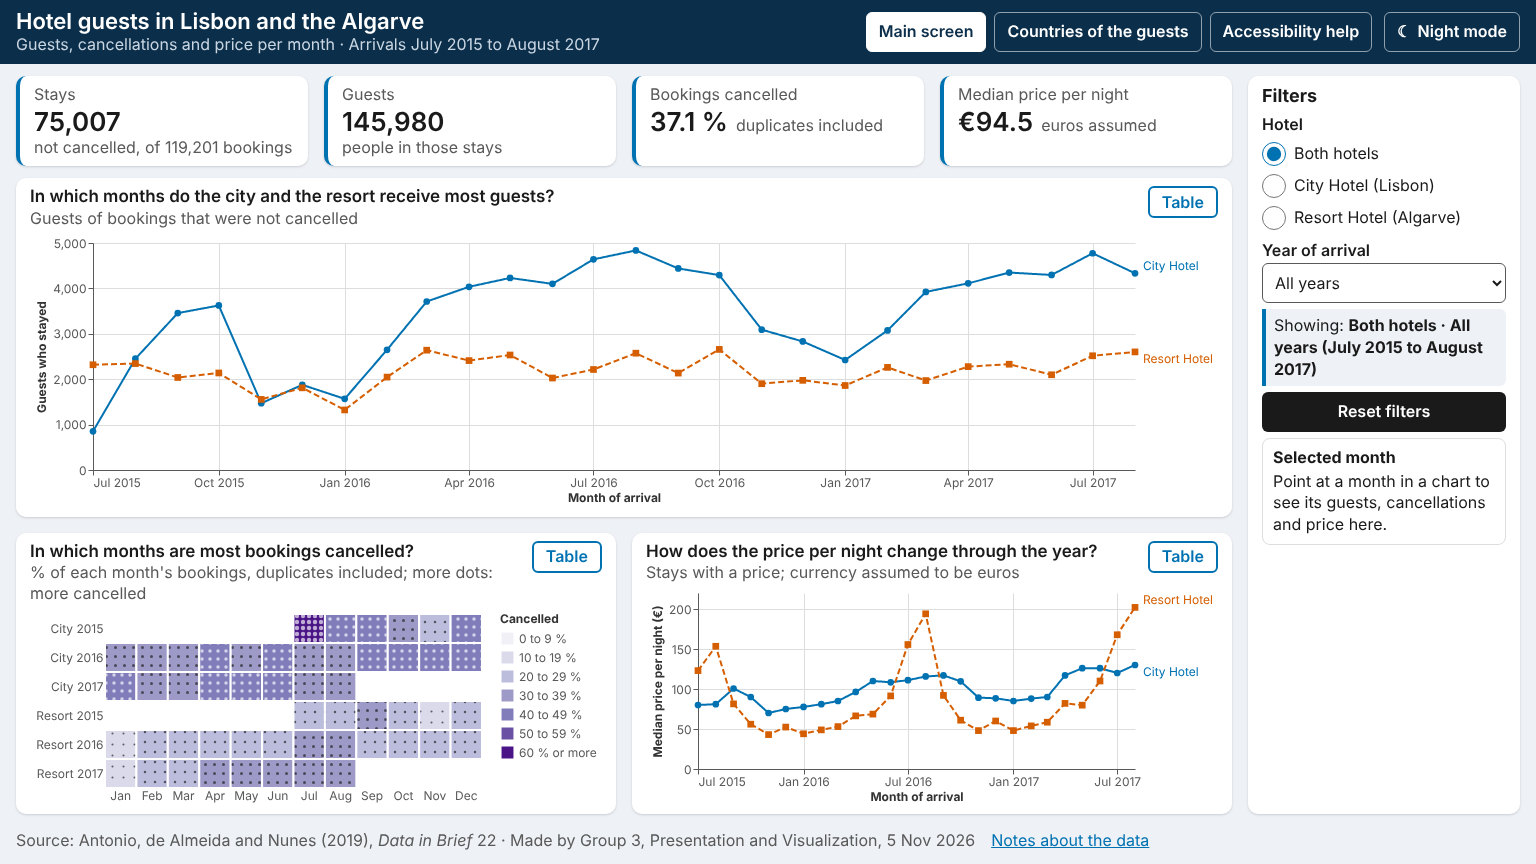

detail.html light


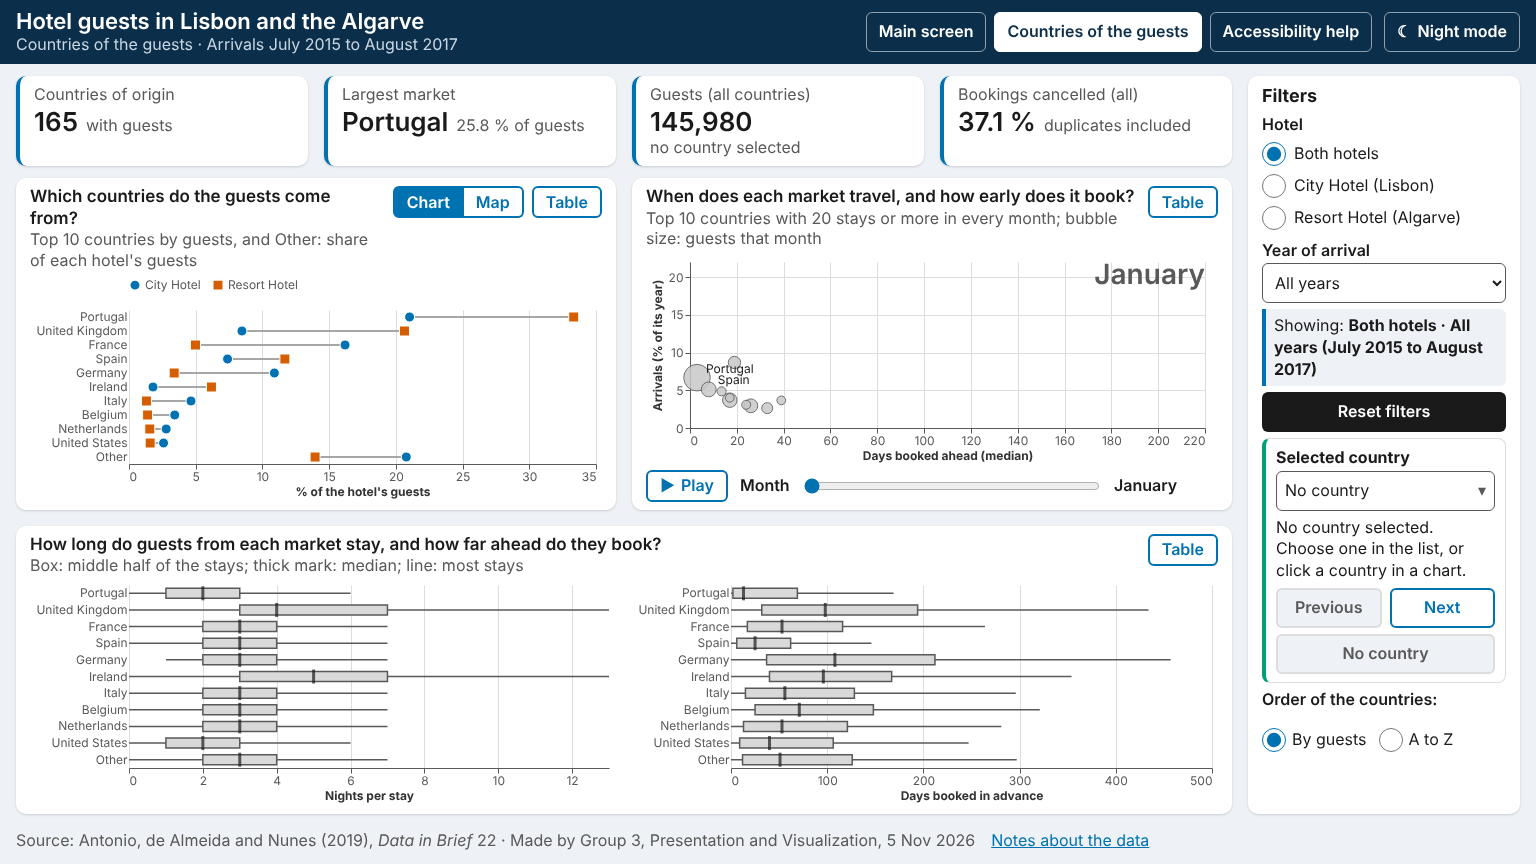

index.html dark


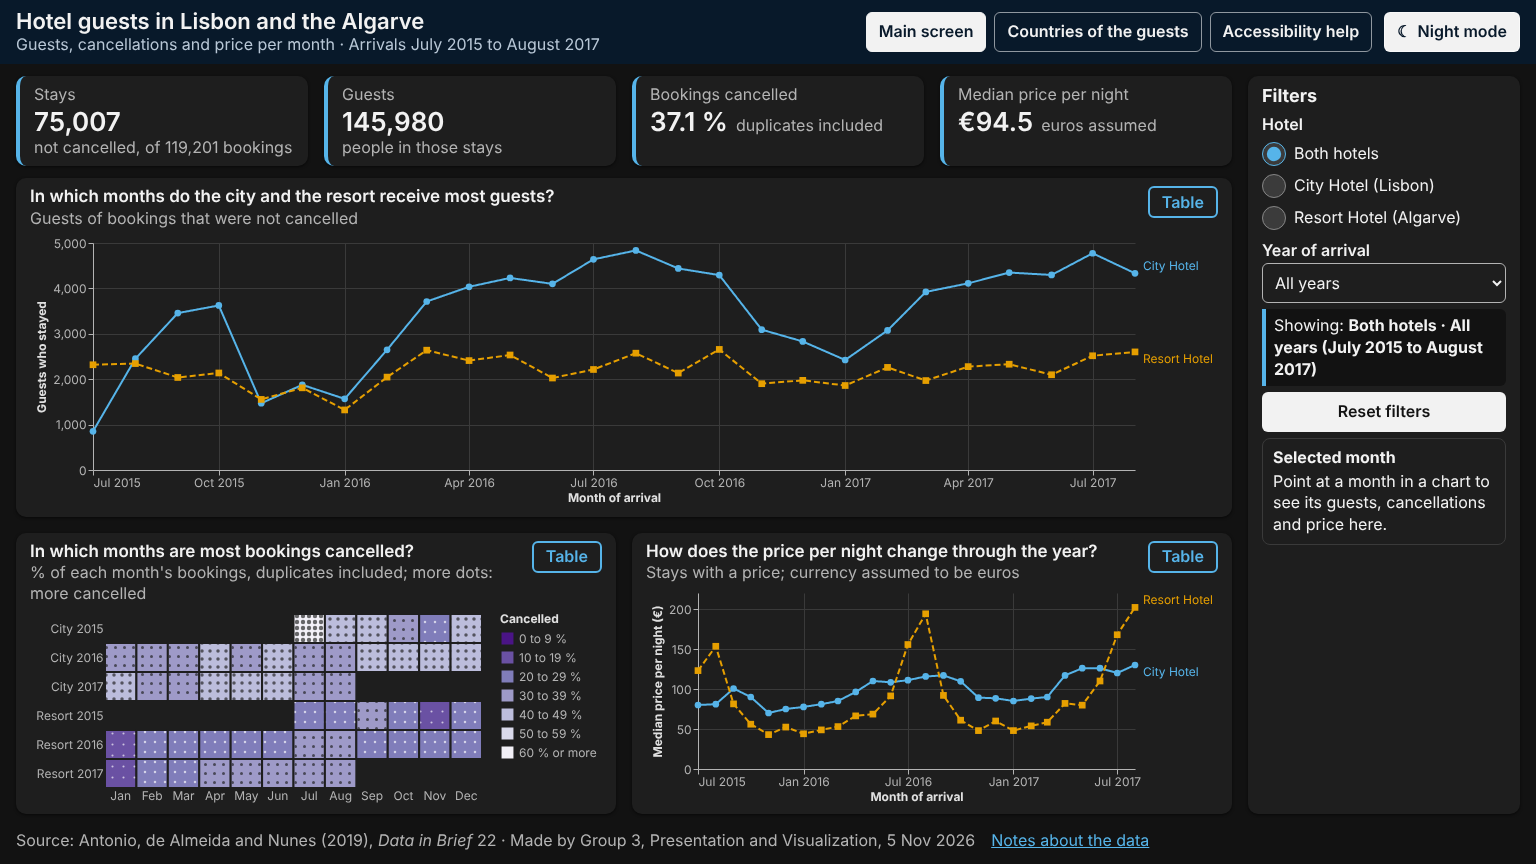

detail.html dark


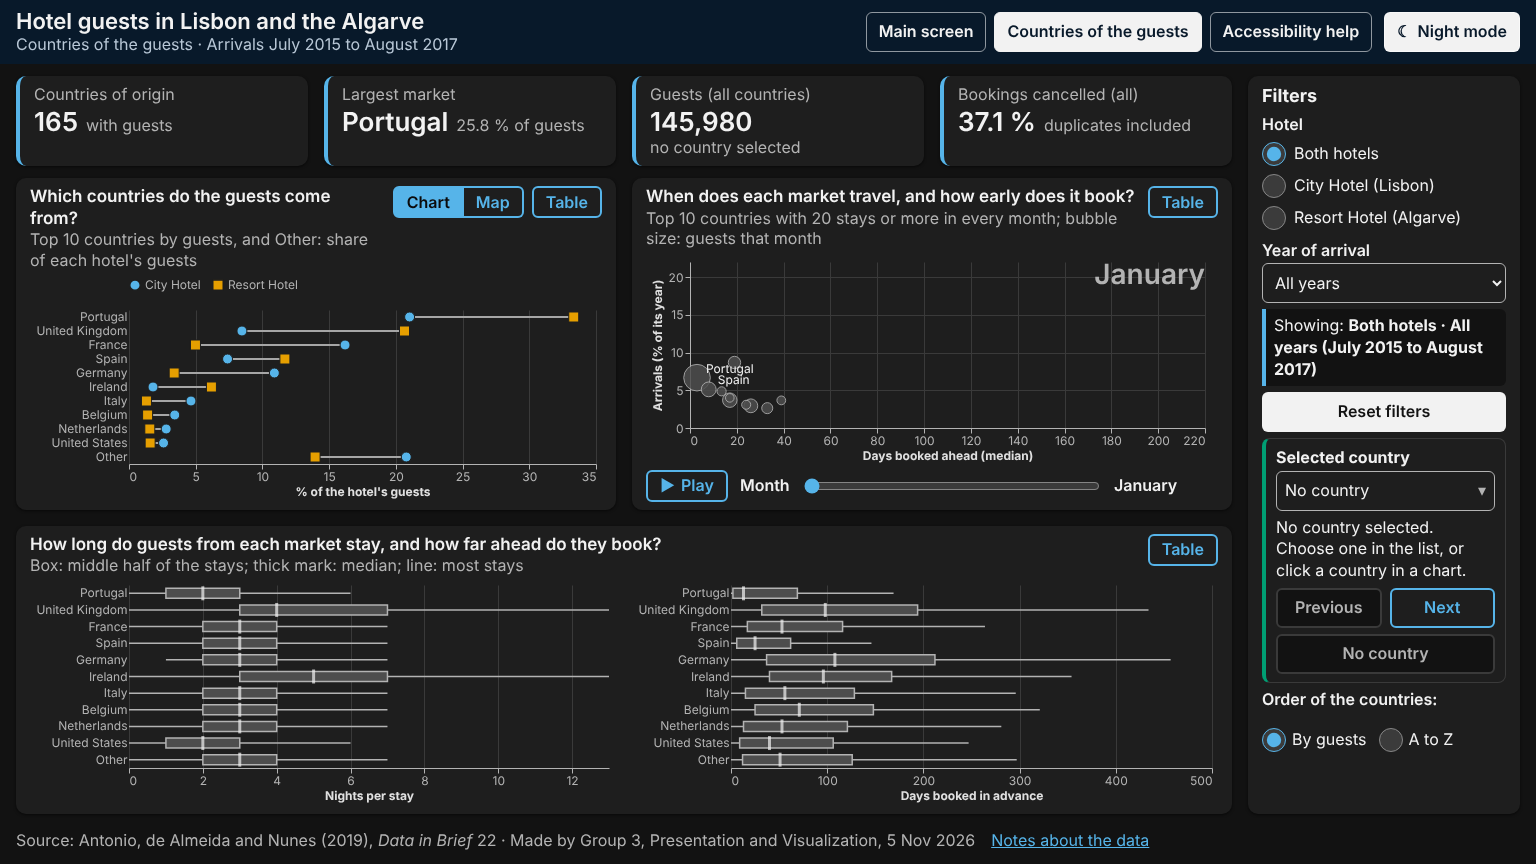

In [22]:
# ── Screenshots on a 16:9 screen (1536 x 864 px), light theme and night mode ──
from IPython.display import Image, display
for scheme in ['light', 'dark']:
    for name in PAGES:
        print(name, scheme)
        display(Image(filename=OUTPUT_DIR / f"{name.replace('.html', '')}_{scheme}_1536x864.png", width=768))

## 6. Export

In [23]:
# ── Export the results ────────────────────────────────────────────────────────
summary.to_csv(OUTPUT_DIR / 'first_load_checks.csv', index=False)
fit_checks.to_csv(OUTPUT_DIR / 'window_fit_checks.csv', index=False)
interaction_checks.to_csv(OUTPUT_DIR / 'interaction_checks.csv', index=False)
keyboard_checks.to_csv(OUTPUT_DIR / 'keyboard_checks.csv', index=False)
operability.to_csv(OUTPUT_DIR / 'wcag_operability_review.csv', index=False)
alternative_checks.to_csv(OUTPUT_DIR / 'text_alternative_checks.csv', index=False)
text_audit.to_csv(OUTPUT_DIR / 'contrast_and_text_size.csv', index=False)
layout_checks.to_csv(OUTPUT_DIR / 'zoom_and_tablet_checks.csv', index=False)
structure_checks.to_csv(OUTPUT_DIR / 'page_structure_checks.csv', index=False)
review.to_csv(OUTPUT_DIR / 'wcag_other_items_review.csv', index=False)
pd.DataFrame([(r['page'], r['scheme'], label, value, context) for r in first_load for label, value, context in r['kpis']],
             columns=['page', 'theme', 'KPI', 'value', 'context']).to_csv(OUTPUT_DIR / 'first_load_kpis.csv', index=False)
print('All checks of this notebook pass:', bool(pd.DataFrame(checks)['passes'].all()), f'({len(checks)} checks)')
sorted(path.name for path in OUTPUT_DIR.iterdir())

All checks of this notebook pass: True (135 checks)


['contrast_and_text_size.csv',
 'detail_200_768x432.png',
 'detail_country_selected_1536x864.png',
 'detail_dark_1536x864.png',
 'detail_keyboard_focus_1536x864.png',
 'detail_light_1536x864.png',
 'detail_map_1536x864.png',
 'detail_tablet_1024x768.png',
 'detail_tablet_768x1024.png',
 'first_load_checks.csv',
 'first_load_kpis.csv',
 'index_200_768x432.png',
 'index_dark_1536x864.png',
 'index_keyboard_focus_1536x864.png',
 'index_light_1536x864.png',
 'index_month_linked_1536x864.png',
 'index_night_mode_1536x864.png',
 'index_tablet_1024x768.png',
 'index_tablet_768x1024.png',
 'interaction_checks.csv',
 'keyboard_checks.csv',
 'page_structure_checks.csv',
 'text_alternative_checks.csv',
 'wcag_operability_review.csv',
 'wcag_other_items_review.csv',
 'window_fit_checks.csv',
 'zoom_and_tablet_checks.csv']

## Conclusions

### Task 6.4 (pages)
1. `index.html` and `detail.html` open by double-click, with no server and no internet: the data, the chart specs, the theme script and the Vega libraries are all local files loaded with `<script src>`.
2. Both show data at first load, in the light theme and in the night mode: four KPIs and every chart, as SVG, with no error in the console, and both fit a 16:9 window of 1536 × 864 px or more without scrolling.
3. Each page has `lang="en"`, skip links to the charts and the filters, and a heading for each chart.

### Task 6.5 (interactions)
1. The twelve interactions of Part 5 work in the browser; each check reads the result back from the page and compares it with the tables of task 6.1.
2. Every change is announced: the "Showing" line and the "Selected month" and "Selected country" boxes are live regions, and the reset, sort order, Chart / Map switch, animation and night mode are announced by a hidden message; the Table and Night mode buttons use `aria-pressed`.

### Task 6.6 (keyboard and focus)
1. Both screens can be used with the keyboard only; every data mark is reachable with the arrow keys and `Alt` + up/down arrow between series, with an SVG focus ring, a live announcement and a visible value box. On the detail screen, Enter selects or clears the focused country.
2. The Operability items of the WCAG checklist are reviewed in section 4.4: all met except the size of the data points (partly met, with other ways to do the same) and the phone item (not applicable).

### Task 6.7 (text alternatives and help)
1. Every chart has a short and a long text alternative and a data table, equal to pandas; the heatmap and the selected country have fill patterns; `accessibility.html` explains the keys, the filters, the new controls and how to report a problem.
2. The Perception, Comprehensibility, Robustness and help-page items are reviewed in section 4.7.

### Limitations
- Checked in Chromium only (headless) and with the keyboard simulated by Playwright; no real screen reader was used, so the students should try the pages with NVDA or VoiceOver.
- 200 % zoom is simulated with a 768 x 432 viewport at device scale 2, which is how browsers lay out a zoomed page.
- Windows smaller than 1536 x 864 px scroll down a little (section 4.1).

### Next steps
- Task 6.8: screenshots of both screens and the final review with the students.